# CCS Final Project — Absolute Conflict RT Model Pipeline

Organized analysis record for the delay-discounting choice+RT modelling
pipeline, covering the absolute-conflict RT model
(`mu = a - b|delta_V|`) and the choice-only baseline. Structured into four
parts:

- **Part 1** — data processing, likelihoods, single-subject sanity fit, and
  the full 99-subject run-A fit.
- **Part 2** — Parameter Recovery.
- **Part 3** — Reliability, run A vs. run B.
- **Part 4** — Out-of-sample Prediction and Value of the RT Modality.

Standardized CSV result tables are written to `results/` after each part, and
the parameter-recovery figures to `figures/`.


# Part 1 — Data Processing, Likelihoods, and Run-A Fitting

Loads the 99-subject delay-discounting data set, applies the preprocessing
rules (NaN removal, missing-choice removal, RT bounds, IQR outlier removal),
computes each subject's fixed non-decision-time `shift`, defines the choice
and RT likelihoods for the absolute-conflict model and the choice-only
baseline, sanity-checks the pipeline on one subject, and then fits every
subject on run A using per-participant MAP with a 6-candidate multi-start
pool.


## 1.0 Setup and constants

In [1]:
import os
import glob
import random

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# Folder containing the per-subject .mat files (relative to this notebook)
DATA_DIR = "DD_data"

# Verified data structure (loaded with scipy.io.loadmat, checked across all 99
# subject files): the data matrices have 7 columns. The original data_labels
# strings are:
#   1. immOutcome                                  -> immediate reward amount (r_imm)
#   2. delOutcome                                   -> delayed reward amount (r_del)
#   3. delay                                        -> delay in days
#   4. action (1=immediate, 2=delayed, 0=missing)   -> choice
#   5. p_imm                                        -> experimental condition parameter
#   6. condition (1=reward,2=loss)                  -> condition
#   7. RT                                           -> reaction time (milliseconds)
# We rename these to the column names used throughout this notebook.
COLUMN_NAMES = ["r_imm", "r_del", "delay", "choice", "p_imm", "condition", "RT"]

random.seed(42)  # reproducibility for the "randomly pick 3 subjects" step below

# Every RT-model-specific file this notebook produces is tagged with this
# name, so results produced with a different mu function do not overwrite
# these.
MODEL_NAME = "absolute_conflict"

FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Standardized result tables will be saved under: {RESULTS_DIR}/")


Standardized result tables will be saved under: results/


## 1.1 Loading the .mat files

Each subject's `.mat` file is read with `scipy.io.loadmat` (these are not
HDF5/v7.3 files, so `h5py` is not needed).


In [2]:
def load_subject_mat(filepath):
    """Load a single subject's .mat file.

    Returns a dict with keys 'subject_id', 'train', 'test', where 'train'
    and 'test' are pandas DataFrames with columns COLUMN_NAMES.
    """
    mat = sio.loadmat(filepath)
    train_df = pd.DataFrame(mat["data_train"], columns=COLUMN_NAMES)
    test_df = pd.DataFrame(mat["data_test"], columns=COLUMN_NAMES)
    subject_id = os.path.splitext(os.path.basename(filepath))[0]
    return {"subject_id": subject_id, "train": train_df, "test": test_df}


def load_all_subjects(data_dir):
    """Load every subject's .mat file in data_dir. Returns {subject_id: {'train': df, 'test': df}}."""
    filepaths = sorted(glob.glob(os.path.join(data_dir, "*.mat")))
    subjects = {}
    for fp in filepaths:
        record = load_subject_mat(fp)
        subjects[record["subject_id"]] = {"train": record["train"], "test": record["test"]}
    return subjects


raw_subjects = load_all_subjects(DATA_DIR)
print(f"Number of subjects loaded: {len(raw_subjects)}")

example_id = sorted(raw_subjects.keys())[0]


Number of subjects loaded: 99


## 1.2 Preprocessing

Order: (0) drop any trial with a NaN in any of the 7 columns — added after
finding raw NaN values in the data (in `RT`, and in `r_imm` for a few
subjects) that steps 1-3 alone would not catch; (1) drop missing-choice
trials (`choice == 0`); (2) drop `RT < 200` ms; (3) drop `RT > Q3 + 3*IQR`,
with Q1/Q3/IQR computed per subject/run on the data remaining after steps
0-2.


In [3]:
def preprocess_run(df):
    """Preprocess a single subject/run DataFrame.

    Returns (cleaned_df, info) where info records how many trials were
    removed at each step.
    """
    n_before = len(df)

    step0 = df.dropna(axis=0, how="any")
    n_after_nan = len(step0)

    step1 = step0[step0["choice"] != 0].copy()
    n_after_missing = len(step1)

    step2 = step1[step1["RT"] >= 200].copy()
    n_after_rt_low = len(step2)

    q1 = step2["RT"].quantile(0.25)
    q3 = step2["RT"].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 3 * iqr
    step3 = step2[step2["RT"] <= upper_bound].copy()
    n_after_rt_high = len(step3)

    info = {
        "n_before": n_before,
        "n_removed_nan": n_before - n_after_nan,
        "n_removed_missing_choice": n_after_nan - n_after_missing,
        "n_removed_rt_low": n_after_missing - n_after_rt_low,
        "n_removed_rt_high": n_after_rt_low - n_after_rt_high,
        "n_after": n_after_rt_high,
        "rt_iqr_q1": q1,
        "rt_iqr_q3": q3,
        "rt_iqr_upper_bound": upper_bound,
    }
    return step3.reset_index(drop=True), info


clean_subjects = {}
preprocess_info = {}

for subject_id, runs in raw_subjects.items():
    clean_train, info_train = preprocess_run(runs["train"])
    clean_test, info_test = preprocess_run(runs["test"])
    clean_subjects[subject_id] = {"train": clean_train, "test": clean_test}
    preprocess_info[subject_id] = {"train": info_train, "test": info_test}

print("Preprocessing complete for all subjects.")


Preprocessing complete for all subjects.


## 1.3 Computing each subject's shift (non-decision time)

In [4]:
def compute_shift(train_rt, test_rt):
    """shift = 0.8 * min(RT), over the pooled, already-cleaned RT from both runs.

    A single shift value is produced per subject and reused for both runs --
    this guarantees RT - shift > 0 in both runs.
    """
    pooled_rt = pd.concat([train_rt, test_rt])
    return 0.8 * pooled_rt.min()


shift_values = {}
for subject_id, runs in clean_subjects.items():
    shift_values[subject_id] = compute_shift(runs["train"]["RT"], runs["test"]["RT"])

print("Computed shift values for all subjects.")


Computed shift values for all subjects.


## 1.4 Data-cleaning check (3 random subjects)

Randomly pick 3 subjects and show, before vs. after preprocessing: trial
counts (run A / run B, with the count removed at each step) and RT
mean/median/range.


In [5]:
sample_subject_ids = random.sample(sorted(raw_subjects.keys()), 3)
print("Randomly selected subjects:", sample_subject_ids)


def rt_summary(rt_series):
    return {
        "mean": rt_series.mean(),
        "median": rt_series.median(),
        "min": rt_series.min(),
        "max": rt_series.max(),
        "range": rt_series.max() - rt_series.min(),
    }


for subject_id in sample_subject_ids:
    print("=" * 70)
    print(f"Subject: {subject_id}")
    print(f"shift (pooled train+test, computed once): {shift_values[subject_id]:.1f}")

    for run_name in ["train", "test"]:
        raw_df = raw_subjects[subject_id][run_name]
        clean_df = clean_subjects[subject_id][run_name]
        info = preprocess_info[subject_id][run_name]

        run_label = "A (train)" if run_name == "train" else "B (test)"
        print(f"\n--- run {run_label} ---")
        print(
            f"trial count: before={info['n_before']}, "
            f"removed_nan={info['n_removed_nan']}, "
            f"removed_missing_choice={info['n_removed_missing_choice']}, "
            f"removed_rt_low={info['n_removed_rt_low']}, "
            f"removed_rt_high={info['n_removed_rt_high']}, "
            f"after={info['n_after']} "
            f"(removed fraction={100 * (1 - info['n_after'] / info['n_before']):.1f}%)"
        )
        raw_stats = rt_summary(raw_df["RT"])
        clean_stats = rt_summary(clean_df["RT"])
        print(
            "RT (before): "
            f"mean={raw_stats['mean']:.1f}, median={raw_stats['median']:.1f}, "
            f"min={raw_stats['min']:.1f}, max={raw_stats['max']:.1f}, range={raw_stats['range']:.1f}"
        )
        print(
            "RT (after): "
            f"mean={clean_stats['mean']:.1f}, median={clean_stats['median']:.1f}, "
            f"min={clean_stats['min']:.1f}, max={clean_stats['max']:.1f}, range={clean_stats['range']:.1f}"
        )


Randomly selected subjects: ['Sample2_omvtibgki', 'Sample1_7wtuwovob', 'Sample1_1pwx30q0h']
Subject: Sample2_omvtibgki
shift (pooled train+test, computed once): 412.9

--- run A (train) ---
trial count: before=100, removed_nan=0, removed_missing_choice=0, removed_rt_low=0, removed_rt_high=1, after=99 (removed fraction=1.0%)
RT (before): mean=1505.3, median=1365.0, min=709.6, max=4981.5, range=4271.9
RT (after): mean=1470.2, median=1355.2, min=709.6, max=2917.9, range=2208.3

--- run B (test) ---
trial count: before=225, removed_nan=0, removed_missing_choice=0, removed_rt_low=0, removed_rt_high=0, after=225 (removed fraction=0.0%)
RT (before): mean=1304.8, median=1192.3, min=516.1, max=2818.6, range=2302.5
RT (after): mean=1304.8, median=1192.3, min=516.1, max=2818.6, range=2302.5
Subject: Sample1_7wtuwovob
shift (pooled train+test, computed once): 793.3

--- run A (train) ---
trial count: before=80, removed_nan=1, removed_missing_choice=0, removed_rt_low=0, removed_rt_high=5, after=74 

## 1.5 Aggregate exclusion statistics (all 99 subjects, run A + run B combined)

In [6]:
total_before = 0
total_removed_nan = 0
total_removed_missing = 0
total_removed_rt_low = 0
total_removed_rt_high = 0
total_after = 0

per_subject_before = {}
per_subject_after = {}

for subject_id, runs_info in preprocess_info.items():
    for run_name in ["train", "test"]:
        info = runs_info[run_name]
        total_before += info["n_before"]
        total_removed_nan += info["n_removed_nan"]
        total_removed_missing += info["n_removed_missing_choice"]
        total_removed_rt_low += info["n_removed_rt_low"]
        total_removed_rt_high += info["n_removed_rt_high"]
        total_after += info["n_after"]
    per_subject_before[subject_id] = runs_info["train"]["n_before"] + runs_info["test"]["n_before"]
    per_subject_after[subject_id] = runs_info["train"]["n_after"] + runs_info["test"]["n_after"]

total_removed = total_before - total_after

print("Aggregate exclusion statistics (all subjects, run A + run B combined)")
print(f"Total trials before preprocessing: {total_before}")
print(f"Removed due to NaN in any column: {total_removed_nan} ({100 * total_removed_nan / total_before:.2f}%)")
print(f"Removed due to missing choice: {total_removed_missing} ({100 * total_removed_missing / total_before:.2f}%)")
print(f"Removed due to RT < 200ms: {total_removed_rt_low} ({100 * total_removed_rt_low / total_before:.2f}%)")
print(
    f"Removed due to RT IQR upper-bound outliers: {total_removed_rt_high} "
    f"({100 * total_removed_rt_high / total_before:.2f}%)"
)
print(f"Total trials after preprocessing: {total_after}")
print(f"Total trials removed: {total_removed} (overall removal fraction = {100 * total_removed / total_before:.2f}%)")

removal_ratio = pd.Series(
    {sid: 1 - per_subject_after[sid] / per_subject_before[sid] for sid in per_subject_before},
    name="removal_ratio",
)
print("\nPer-subject removal ratio (run A + run B combined), distribution:")
print((removal_ratio * 100).describe().round(2).to_string())

high_removal_threshold = 0.20
high_removal_subjects = removal_ratio[removal_ratio > high_removal_threshold].sort_values(ascending=False)
if len(high_removal_subjects) > 0:
    print(f"\nSubjects with removal ratio above {high_removal_threshold * 100:.0f}%:")
    for subject_id, ratio in high_removal_subjects.items():
        print(f"  {subject_id}: {ratio * 100:.2f}%")
else:
    print(f"\nNo subject has a removal ratio above {high_removal_threshold * 100:.0f}%.")


Aggregate exclusion statistics (all subjects, run A + run B combined)
Total trials before preprocessing: 28990
Removed due to NaN in any column: 152 (0.52%)
Removed due to missing choice: 0 (0.00%)
Removed due to RT < 200ms: 0 (0.00%)
Removed due to RT IQR upper-bound outliers: 363 (1.25%)
Total trials after preprocessing: 28475
Total trials removed: 515 (overall removal fraction = 1.78%)

Per-subject removal ratio (run A + run B combined), distribution:
count    99.00
mean      1.80
std       2.03
min       0.00
25%       0.38
50%       1.15
75%       2.31
max       9.62

No subject has a removal ratio above 20%.


## Choice proportions and RT distributions

Pooled across all subjects, on the cleaned data, for the reward condition
(the only condition with data in this data set -- see Part 4). Reported
separately for run A and run B.


In [7]:
def condition_descriptives(clean_subjects_dict, run_name):
    """Pooled choice-proportion-delayed and RT descriptives for one run,
    reward condition only (condition == 1), across all subjects.
    """
    pooled = pd.concat([runs[run_name] for runs in clean_subjects_dict.values()], ignore_index=True)
    reward = pooled[pooled["condition"] == 1]
    return {
        "n_trials": len(reward),
        "prop_delayed": (reward["choice"] == 2).mean(),
        "rt_mean": reward["RT"].mean(),
        "rt_sd": reward["RT"].std(),
        "rt_median": reward["RT"].median(),
    }


run_a_desc = condition_descriptives(clean_subjects, "train")
run_b_desc = condition_descriptives(clean_subjects, "test")

print("Run A (reward condition, pooled across all subjects):")
print(f"  n_trials = {run_a_desc['n_trials']}")
print(f"  proportion delayed = {100 * run_a_desc['prop_delayed']:.1f}%")
print(f"  RT mean (SD) = {run_a_desc['rt_mean']:.1f} ({run_a_desc['rt_sd']:.1f}) ms")
print(f"  RT median = {run_a_desc['rt_median']:.1f} ms")

print("\nRun B (reward condition, pooled across all subjects):")
print(f"  n_trials = {run_b_desc['n_trials']}")
print(f"  proportion delayed = {100 * run_b_desc['prop_delayed']:.1f}%")
print(f"  RT mean (SD) = {run_b_desc['rt_mean']:.1f} ({run_b_desc['rt_sd']:.1f}) ms")
print(f"  RT median = {run_b_desc['rt_median']:.1f} ms")

print(
    f"\nSince mean > median in both runs (run A: {run_a_desc['rt_mean']:.1f} > {run_a_desc['rt_median']:.1f}; "
    f"run B: {run_b_desc['rt_mean']:.1f} > {run_b_desc['rt_median']:.1f}), the RT distribution is right-skewed in both runs."
)


Run A (reward condition, pooled across all subjects):
  n_trials = 8794
  proportion delayed = 45.2%
  RT mean (SD) = 1877.4 (811.3) ms
  RT median = 1707.7 ms

Run B (reward condition, pooled across all subjects):
  n_trials = 19681
  proportion delayed = 60.0%
  RT mean (SD) = 1664.1 (816.7) ms
  RT median = 1493.9 ms

Since mean > median in both runs (run A: 1877.4 > 1707.7; run B: 1664.1 > 1493.9), the RT distribution is right-skewed in both runs.


## 1.6 Valuation model and choice likelihood

`V = A / (1 + k * D)` (hyperbolic discounting), `D = 0` for the immediate
option. `delta_V = V_delayed - V_immediate`. Choice follows a softmax rule:
`P(delayed) = sigmoid(beta * delta_V)`.


In [8]:
def hyperbolic_value(amount, delay, k):
    """Hyperbolic discounting value: V = amount / (1 + k * delay)."""
    return amount / (1 + k * delay)


def compute_delta_v(df, k):
    """delta_V = V_delayed - V_immediate for every trial in df (immediate option has delay = 0)."""
    v_immediate = hyperbolic_value(df["r_imm"].to_numpy(), 0.0, k)
    v_delayed = hyperbolic_value(df["r_del"].to_numpy(), df["delay"].to_numpy(), k)
    return v_delayed - v_immediate


def log_sigmoid(x):
    """Numerically stable log(sigmoid(x)) = -log(1 + exp(-x))."""
    return -np.logaddexp(0.0, -x)


def choice_log_likelihood(df, k, beta):
    """Sum of per-trial log p(choice | delta_V, beta) under the softmax choice rule."""
    delta_v = compute_delta_v(df, k)
    chose_delayed = df["choice"].to_numpy() == 2
    sign = np.where(chose_delayed, 1.0, -1.0)
    return log_sigmoid(sign * beta * delta_v).sum()


## 1.7 RT likelihood (shifted log-normal, absolute-conflict model)

`RT ~ LogNormal(location=mu, scale=sigma, shift=shift)`, i.e.
`log(RT - shift) ~ Normal(mu, sigma)`, with `mu = a - b * |delta_V|`. `shift`
is the fixed, subject-specific value from Section 1.3.


In [9]:
def mu_absolute_conflict(delta_v, a, b):
    """Location parameter of the absolute-conflict RT model: mu = a - b * |delta_V|.

    Naming convention: mu_<model_name>(delta_v, a, b) -> array same shape as
    delta_v. This is the pluggable "value -> RT mapping"; every function
    below takes it as a `mu_func` argument (defaulting to MU_FUNC) instead of
    hardcoding the mapping.
    """
    return a - b * np.abs(delta_v)


MU_FUNC = mu_absolute_conflict


def rt_log_likelihood(df, k, a, b, sigma, shift, mu_func=MU_FUNC):
    """Sum of per-trial log-density of RT under a shifted log-normal.

        log p(RT) = -log(RT - shift) - log(sigma) - 0.5*log(2*pi)
                    - (log(RT - shift) - mu)^2 / (2 * sigma^2)
    """
    delta_v = compute_delta_v(df, k)
    mu = mu_func(delta_v, a, b)
    rt_shifted = df["RT"].to_numpy() - shift
    log_rt_shifted = np.log(rt_shifted)
    trial_log_lik = (
        -log_rt_shifted - np.log(sigma) - 0.5 * np.log(2 * np.pi) - (log_rt_shifted - mu) ** 2 / (2 * sigma ** 2)
    )
    return trial_log_lik.sum()


## 1.8 Priors and the MAP objective

| parameter | prior |
|---|---|
| k | HalfNormal(scale=1) |
| beta | HalfNormal(scale=5) |
| a | Normal(mean=log(subject's median RT), sd=2) |
| b | HalfNormal(scale=2) |
| sigma | HalfNormal(scale=1) |

`beta` is estimated independently for the full model and the choice-only
baseline (not shared).


In [10]:
PRIOR_SCALES = {"k": 1.0, "beta": 5.0, "a_sd": 2.0, "b": 2.0, "sigma": 1.0}


def log_prior_full(k, beta, a, b, sigma, a_prior_mean):
    return (
        stats.halfnorm.logpdf(k, scale=PRIOR_SCALES["k"])
        + stats.halfnorm.logpdf(beta, scale=PRIOR_SCALES["beta"])
        + stats.norm.logpdf(a, loc=a_prior_mean, scale=PRIOR_SCALES["a_sd"])
        + stats.halfnorm.logpdf(b, scale=PRIOR_SCALES["b"])
        + stats.halfnorm.logpdf(sigma, scale=PRIOR_SCALES["sigma"])
    )


def log_prior_baseline(k, beta):
    return stats.halfnorm.logpdf(k, scale=PRIOR_SCALES["k"]) + stats.halfnorm.logpdf(beta, scale=PRIOR_SCALES["beta"])


def negative_log_posterior_full(params, df, shift, a_prior_mean, mu_func=MU_FUNC):
    """params = [k, beta, a, b, sigma]. mu_func is forwarded to rt_log_likelihood, not hardcoded."""
    k, beta, a, b, sigma = params
    log_lik = choice_log_likelihood(df, k, beta) + rt_log_likelihood(df, k, a, b, sigma, shift, mu_func)
    log_prior = log_prior_full(k, beta, a, b, sigma, a_prior_mean)
    return -(log_lik + log_prior)


def negative_log_posterior_baseline(params, df):
    """params = [k, beta]. The RT term is dropped entirely from the likelihood."""
    k, beta = params
    log_lik = choice_log_likelihood(df, k, beta)
    log_prior = log_prior_baseline(k, beta)
    return -(log_lik + log_prior)


FULL_PARAM_NAMES = ["k", "beta", "a", "b", "sigma"]
BASELINE_PARAM_NAMES = ["k", "beta"]

FULL_BOUNDS = [
    (1e-6, 10),    # k
    (1e-6, 50),    # beta
    (None, None),  # a: no hard bound, softly constrained by its prior
    (0, 20),       # b
    (1e-6, 5),     # sigma
]
BASELINE_BOUNDS = [(1e-6, 10), (1e-6, 50)]


## 1.9 Single-subject sanity fit (run A)

Fits one subject with `scipy.optimize.minimize`, `method="L-BFGS-B"`, to
confirm the whole pipeline runs correctly before fitting all 99 subjects.


In [11]:
fit_subject_id = example_id
fit_df = clean_subjects[fit_subject_id]["train"]
fit_shift = shift_values[fit_subject_id]
fit_a_prior_mean = np.log(fit_df["RT"].median())

full_x0 = [0.05, 1.0, fit_a_prior_mean, 0.1, 0.5]
baseline_x0 = [0.05, 1.0]

full_result = minimize(
    negative_log_posterior_full, x0=full_x0, args=(fit_df, fit_shift, fit_a_prior_mean),
    method="L-BFGS-B", bounds=FULL_BOUNDS,
)
baseline_result = minimize(
    negative_log_posterior_baseline, x0=baseline_x0, args=(fit_df,),
    method="L-BFGS-B", bounds=BASELINE_BOUNDS,
)

print(f"Fitting subject: {fit_subject_id} ({len(fit_df)} run-A trials)")
print("\nFull model (choice + RT):")
for name, value in zip(FULL_PARAM_NAMES, full_result.x):
    print(f"  {name} = {value:.4f}")
print(f"  converged (success): {full_result.success}")

print("\nChoice-only baseline:")
for name, value in zip(BASELINE_PARAM_NAMES, baseline_result.x):
    print(f"  {name} = {value:.4f}")
print(f"  converged (success): {baseline_result.success}")


Fitting subject: Sample1_07mpzgefw (75 run-A trials)

Full model (choice + RT):
  k = 0.0141
  beta = 0.2790
  a = 7.0239
  b = 0.0087
  sigma = 0.5479
  converged (success): True

Choice-only baseline:
  k = 0.0146
  beta = 0.2758
  converged (success): True


## 1.10 Checking whether any parameter is stuck at a bound

In [12]:
def check_bounds(param_names, values, bounds, tol=1e-4):
    """Report which parameters ended up at (or extremely close to) a bound."""
    flags = []
    for name, value, (lower, upper) in zip(param_names, values, bounds):
        if lower is not None and abs(value - lower) < tol:
            flags.append((name, "lower", lower))
        if upper is not None and abs(value - upper) < tol:
            flags.append((name, "upper", upper))
    return flags


full_bound_flags = check_bounds(FULL_PARAM_NAMES, full_result.x, FULL_BOUNDS)
baseline_bound_flags = check_bounds(BASELINE_PARAM_NAMES, baseline_result.x, BASELINE_BOUNDS)

if full_bound_flags:
    print("Full model - parameters stuck at a bound:")
    for name, side, bound_value in full_bound_flags:
        print(f"  {name} is at its {side} bound ({bound_value})")
else:
    print("Full model - no parameter is stuck at a bound.")

if baseline_bound_flags:
    print("\nBaseline - parameters stuck at a bound:")
    for name, side, bound_value in baseline_bound_flags:
        print(f"  {name} is at its {side} bound ({bound_value})")
else:
    print("\nBaseline - no parameter is stuck at a bound.")


Full model - no parameter is stuck at a bound.

Baseline - no parameter is stuck at a bound.


## 1.11 Fitting all 99 subjects on run A (multi-start, 6-candidate pool)

Each subject's final estimate is the best (lowest negative log posterior)
of a **6-candidate pool** — one heuristic single start plus 5 random starts
— rather than a single heuristic start alone. Random starts are drawn
uniformly within each bounded parameter's range (`k`, `beta`, `b`, `sigma`);
`a` has no hard bound, so its random starts are drawn from its own prior
instead. The single-start fits (`single_start_full_fits` /
`single_start_baseline_fits`) are computed first and included as one of the
6 candidates, so the adopted estimate is guaranteed to be at least as good
as a plain single-start fit would have been.


In [13]:
MULTI_START_SEED = 2024
N_MULTI_START = 5


def multi_start_fit_full(df, shift, a_prior_mean, bounds, n_starts, rng, mu_func=MU_FUNC):
    """Run n_starts full-model fits from random starting points; return the best."""
    results = []
    for _ in range(n_starts):
        x0 = [
            rng.uniform(1e-6, 10),
            rng.uniform(1e-6, 50),
            rng.normal(a_prior_mean, 2.0),
            rng.uniform(0, 20),
            rng.uniform(1e-6, 5),
        ]
        res = minimize(
            negative_log_posterior_full, x0=x0, args=(df, shift, a_prior_mean, mu_func),
            method="L-BFGS-B", bounds=bounds,
        )
        results.append(res)
    return min(results, key=lambda r: r.fun), results


def multi_start_fit_baseline(df, bounds, n_starts, rng):
    """Run n_starts choice-only-baseline fits from random starting points; return the best."""
    results = []
    for _ in range(n_starts):
        x0 = [rng.uniform(1e-6, 10), rng.uniform(1e-6, 50)]
        res = minimize(negative_log_posterior_baseline, x0=x0, args=(df,), method="L-BFGS-B", bounds=bounds)
        results.append(res)
    return min(results, key=lambda r: r.fun), results


def fit_full_candidate_pool(df, shift, a_prior_mean, rng, n_starts=N_MULTI_START, mu_func=MU_FUNC):
    """Best of {single heuristic start} union {n_starts random starts}."""
    full_x0 = [0.05, 1.0, a_prior_mean, 0.1, 0.5]
    single_res = minimize(
        negative_log_posterior_full, x0=full_x0, args=(df, shift, a_prior_mean, mu_func),
        method="L-BFGS-B", bounds=FULL_BOUNDS,
    )
    best_random, _ = multi_start_fit_full(df, shift, a_prior_mean, FULL_BOUNDS, n_starts, rng, mu_func)
    chosen = best_random if best_random.fun < single_res.fun else single_res
    return {"x": chosen.x, "success": chosen.success, "message": chosen.message, "fun": chosen.fun}


def fit_baseline_candidate_pool(df, rng, n_starts=N_MULTI_START):
    """Best of {single heuristic start} union {n_starts random starts}, choice-only."""
    baseline_x0 = [0.05, 1.0]
    single_res = minimize(
        negative_log_posterior_baseline, x0=baseline_x0, args=(df,), method="L-BFGS-B", bounds=BASELINE_BOUNDS,
    )
    best_random, _ = multi_start_fit_baseline(df, BASELINE_BOUNDS, n_starts, rng)
    chosen = best_random if best_random.fun < single_res.fun else single_res
    return {"x": chosen.x, "success": chosen.success, "message": chosen.message, "fun": chosen.fun}


In [14]:
# Single-start fits, kept only so Section 1.13 can quantify what multi-start changed
single_start_full_fits = {}
single_start_baseline_fits = {}

for subject_id, runs in clean_subjects.items():
    df = runs["train"]
    shift = shift_values[subject_id]
    a_prior_mean = np.log(df["RT"].median())

    full_res = minimize(
        negative_log_posterior_full, x0=[0.05, 1.0, a_prior_mean, 0.1, 0.5],
        args=(df, shift, a_prior_mean), method="L-BFGS-B", bounds=FULL_BOUNDS,
    )
    baseline_res = minimize(
        negative_log_posterior_baseline, x0=[0.05, 1.0], args=(df,), method="L-BFGS-B", bounds=BASELINE_BOUNDS,
    )
    single_start_full_fits[subject_id] = {
        "x": full_res.x, "success": full_res.success, "message": full_res.message, "fun": full_res.fun,
    }
    single_start_baseline_fits[subject_id] = {
        "x": baseline_res.x, "success": baseline_res.success, "message": baseline_res.message, "fun": baseline_res.fun,
    }

print(f"Single-start fits complete for {len(single_start_full_fits)} subjects (kept for comparison only).")


Single-start fits complete for 99 subjects (kept for comparison only).


In [15]:
# Adopted fits: candidate pool of 6 (1 single-start + 5 random starts), never worse than single-start alone
rng = np.random.default_rng(MULTI_START_SEED)

full_fits = {}
baseline_fits = {}

for subject_id, runs in clean_subjects.items():
    df = runs["train"]
    shift = shift_values[subject_id]
    a_prior_mean = np.log(df["RT"].median())

    best_full_random, _ = multi_start_fit_full(df, shift, a_prior_mean, FULL_BOUNDS, N_MULTI_START, rng)
    best_baseline_random, _ = multi_start_fit_baseline(df, BASELINE_BOUNDS, N_MULTI_START, rng)

    single_full = single_start_full_fits[subject_id]
    single_baseline = single_start_baseline_fits[subject_id]

    if best_full_random.fun < single_full["fun"]:
        full_fits[subject_id] = {
            "x": best_full_random.x, "success": best_full_random.success,
            "message": best_full_random.message, "fun": best_full_random.fun,
        }
    else:
        full_fits[subject_id] = dict(single_full)

    if best_baseline_random.fun < single_baseline["fun"]:
        baseline_fits[subject_id] = {
            "x": best_baseline_random.x, "success": best_baseline_random.success,
            "message": best_baseline_random.message, "fun": best_baseline_random.fun,
        }
    else:
        baseline_fits[subject_id] = dict(single_baseline)

print(
    f"Fits complete for {len(full_fits)} subjects "
    f"(candidate pool: 1 single-start + {N_MULTI_START} random starts per subject per model)."
)


Fits complete for 99 subjects (candidate pool: 1 single-start + 5 random starts per subject per model).


## 1.12 Convergence failures

In [16]:
def failed_ids(fits):
    return [sid for sid, r in fits.items() if not r["success"]]


n_subjects = len(full_fits)

full_failed = failed_ids(full_fits)
baseline_failed = failed_ids(baseline_fits)

print("Full model:")
print(f"  failed: {len(full_failed)} / {n_subjects}")
if full_failed:
    print(f"  subject IDs: {full_failed}")

print("\nChoice-only baseline:")
print(f"  failed: {len(baseline_failed)} / {n_subjects}")
if baseline_failed:
    print(f"  subject IDs: {baseline_failed}")


Full model:
  failed: 0 / 99

Choice-only baseline:
  failed: 1 / 99
  subject IDs: ['Sample1_yzpl1bjpp']


## 1.13 Parameter distributions across subjects (run A, multi-start)

In [17]:
full_params_df = pd.DataFrame({sid: r["x"] for sid, r in full_fits.items()}).T
full_params_df.columns = FULL_PARAM_NAMES

baseline_params_df = pd.DataFrame({sid: r["x"] for sid, r in baseline_fits.items()}).T
baseline_params_df.columns = BASELINE_PARAM_NAMES

print("Full-model parameter estimates, summary statistics across 99 subjects:")
display(full_params_df.describe())
print("Baseline parameter estimates, summary statistics across 99 subjects:")
display(baseline_params_df.describe())


Full-model parameter estimates, summary statistics across 99 subjects:


,k,beta,a,b,sigma
count,99.000000,99.000000,99.000000,99.000000,99.000000
mean,0.057492,1.607173,7.074686,0.005608,0.478002
std,0.130126,1.959036,0.252489,0.004652,0.096949
min,0.000001,0.009915,6.385777,0.000000,0.270866
25%,0.001065,0.280718,6.930429,0.002129,0.408420
50%,0.008835,0.719097,7.085431,0.005124,0.476279
75%,0.014484,1.901491,7.277630,0.007747,0.554551
max,0.642443,8.775996,7.658218,0.021866,0.665540


Baseline parameter estimates, summary statistics across 99 subjects:


,k,beta
count,99.000000,99.000000
mean,0.044045,1.567182
std,0.112657,1.900116
min,0.000001,0.017350
25%,0.001090,0.272655
50%,0.008703,0.717387
75%,0.012048,1.900038
max,0.639982,8.775917


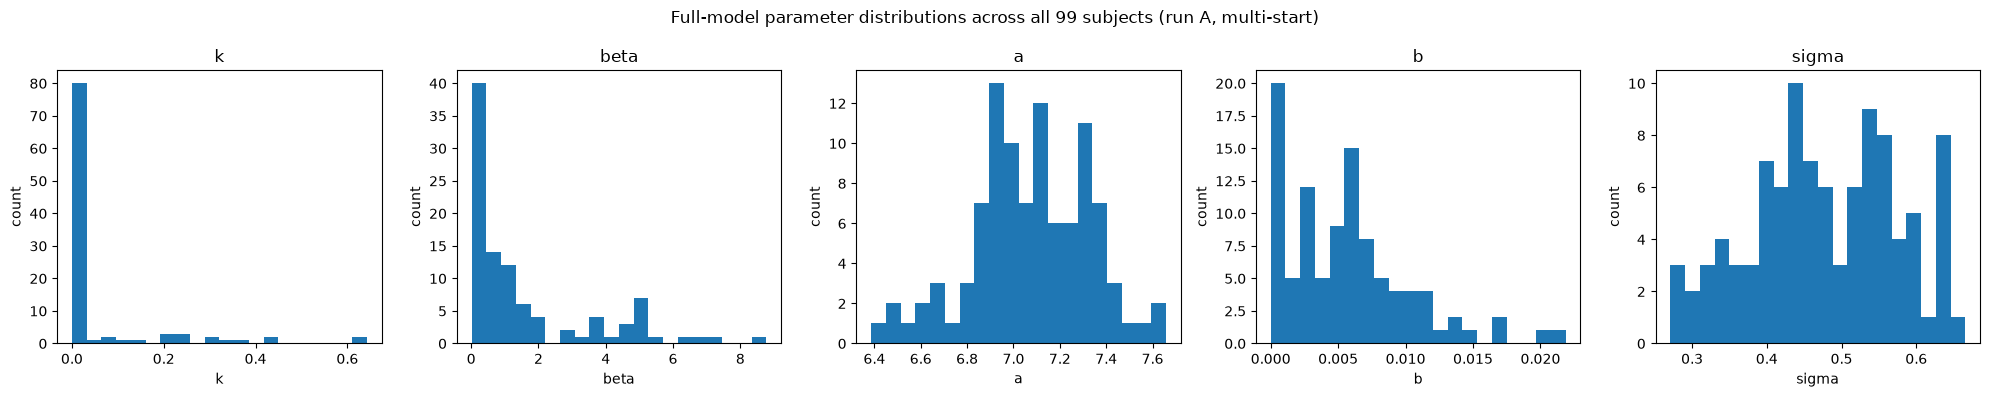

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, name in zip(axes, FULL_PARAM_NAMES):
    ax.hist(full_params_df[name], bins=20)
    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("count")
fig.suptitle("Full-model parameter distributions across all 99 subjects (run A, multi-start)")
plt.tight_layout()
plt.show()


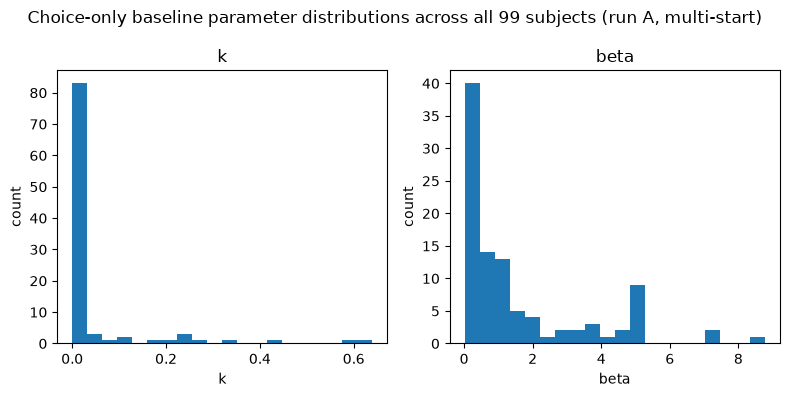

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, name in zip(axes, BASELINE_PARAM_NAMES):
    ax.hist(baseline_params_df[name], bins=20)
    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("count")
fig.suptitle("Choice-only baseline parameter distributions across all 99 subjects (run A, multi-start)")
plt.tight_layout()
plt.show()


## 1.14 Parameters stuck at bounds

In [20]:
def tally_bound_flags(fits, param_names, bounds):
    """Count, per parameter and per bound side, how many subjects are stuck there."""
    counts = {name: {"lower": 0, "upper": 0} for name in param_names}
    subject_ids = {name: {"lower": [], "upper": []} for name in param_names}
    for subject_id, r in fits.items():
        for name, side, _ in check_bounds(param_names, r["x"], bounds):
            counts[name][side] += 1
            subject_ids[name][side].append(subject_id)
    return counts, subject_ids


def print_bound_tally(label, counts, subject_ids, param_names):
    print(f"{label}:")
    any_flag = False
    for name in param_names:
        for side in ["lower", "upper"]:
            count = counts[name][side]
            if count > 0:
                any_flag = True
                print(f"  {name} ({side} bound): {count} subjects -> {subject_ids[name][side]}")
    if not any_flag:
        print("  none")


full_bound_counts, full_bound_subjects = tally_bound_flags(full_fits, FULL_PARAM_NAMES, FULL_BOUNDS)
baseline_bound_counts, baseline_bound_subjects = tally_bound_flags(baseline_fits, BASELINE_PARAM_NAMES, BASELINE_BOUNDS)

print_bound_tally("Full model", full_bound_counts, full_bound_subjects, FULL_PARAM_NAMES)
print()
print_bound_tally("Baseline", baseline_bound_counts, baseline_bound_subjects, BASELINE_PARAM_NAMES)


Full model:
  k (lower bound): 6 subjects -> ['Sample1_3sdxo9cfd', 'Sample1_f3zeh9jib', 'Sample2_2qwq8xyde', 'Sample2_50qhhzl0l', 'Sample2_k5m1dlbmf', 'Sample2_tvlehk06l']
  b (lower bound): 11 subjects -> ['Sample1_t5fyitpcm', 'Sample1_tqjcijs1e', 'Sample1_vowxbo6kk', 'Sample1_wqbicpk3k', 'Sample2_4vubmw9up', 'Sample2_5jvj7f5y4', 'Sample2_82xbgaiuk', 'Sample2_dyww6xmpp', 'Sample2_mjx6wy2sv', 'Sample2_ot3o7pu2r', 'Sample2_ztvocmqgb']

Baseline:
  k (lower bound): 5 subjects -> ['Sample1_3sdxo9cfd', 'Sample1_f3zeh9jib', 'Sample2_2qwq8xyde', 'Sample2_50qhhzl0l', 'Sample2_tvlehk06l']


# Part 2 — Parameter Recovery

For each of the 99 real subjects, one synthetic "twin" is created: its
ground-truth parameters are that subject's own run-A multi-start estimate
(Part 1), and its trial design (`r_imm`, `r_del`, `delay`, `p_imm`,
`condition`) and `shift` are that subject's own cleaned run-A design and
actual `shift` — reusing real, realistic parameter combinations and trial
designs rather than independent per-parameter sampling or an invented
design. The same simulated choice data is refit both with the full model
and with the choice-only baseline, so recovery of `k`/`beta` can be compared
with vs. without RT information.


## 2.1 Simulating synthetic data

Draws `choice` from `Bernoulli(sigmoid(beta_true * delta_V))` and `RT` from
`shift + LogNormal(mu_true, sigma_true)`.


In [21]:
SIMULATION_SEED = 777


def simulate_synthetic_subject(design_df, true_params, shift, rng, mu_func=MU_FUNC):
    """Simulate one synthetic subject's choice and RT columns; other columns are untouched."""
    k_true, beta_true, a_true, b_true, sigma_true = true_params
    delta_v = compute_delta_v(design_df, k_true)
    p_delayed = 1.0 / (1.0 + np.exp(-beta_true * delta_v))
    chose_delayed = rng.random(len(design_df)) < p_delayed
    simulated_choice = np.where(chose_delayed, 2.0, 1.0)

    mu_true = mu_func(delta_v, a_true, b_true)
    simulated_rt = rng.lognormal(mean=mu_true, sigma=sigma_true) + shift

    synthetic_df = design_df.copy()
    synthetic_df["choice"] = simulated_choice
    synthetic_df["RT"] = simulated_rt
    return synthetic_df


sim_rng = np.random.default_rng(SIMULATION_SEED)

synthetic_subjects = {}
true_params_full = {}

for subject_id in sorted(clean_subjects.keys()):
    true_x = full_fits[subject_id]["x"]
    shift = shift_values[subject_id]
    design_df = clean_subjects[subject_id]["train"]
    synthetic_subjects[subject_id] = simulate_synthetic_subject(design_df, true_x, shift, sim_rng)
    true_params_full[subject_id] = true_x

print(f"Simulated synthetic data for {len(synthetic_subjects)} subjects.")


Simulated synthetic data for 99 subjects.


## 2.2 Refitting the synthetic data

Reuses the exact Part-1 candidate-pool procedure (`fit_full_candidate_pool`,
`fit_baseline_candidate_pool`), with a dedicated random seed independent of
Part 1's `MULTI_START_SEED`.


In [22]:
RECOVERY_MULTI_START_SEED = 4048
recovery_rng = np.random.default_rng(RECOVERY_MULTI_START_SEED)

recovery_full_fits = {}
recovery_baseline_fits = {}

for subject_id, synthetic_df in synthetic_subjects.items():
    shift = shift_values[subject_id]
    a_prior_mean = np.log(synthetic_df["RT"].median())
    recovery_full_fits[subject_id] = fit_full_candidate_pool(synthetic_df, shift, a_prior_mean, recovery_rng)
    recovery_baseline_fits[subject_id] = fit_baseline_candidate_pool(synthetic_df, recovery_rng)

print(f"Refitting complete for {len(recovery_full_fits)} synthetic subjects (full model and baseline).")


Refitting complete for 99 synthetic subjects (full model and baseline).


## 2.3 Convergence failures and bound-stuck subjects (recovery fits)

In [23]:
recovery_full_failed = failed_ids(recovery_full_fits)
recovery_baseline_failed = failed_ids(recovery_baseline_fits)
n_synthetic = len(recovery_full_fits)

print("Full model (recovery):")
print(f"  failed: {len(recovery_full_failed)} / {n_synthetic}")
if recovery_full_failed:
    print(f"  failed subject IDs: {recovery_full_failed}")

print("\nChoice-only baseline (recovery):")
print(f"  failed: {len(recovery_baseline_failed)} / {n_synthetic}")
if recovery_baseline_failed:
    print(f"  failed subject IDs: {recovery_baseline_failed}")

recovery_full_bound_counts, recovery_full_bound_subjects = tally_bound_flags(recovery_full_fits, FULL_PARAM_NAMES, FULL_BOUNDS)
recovery_baseline_bound_counts, recovery_baseline_bound_subjects = tally_bound_flags(
    recovery_baseline_fits, BASELINE_PARAM_NAMES, BASELINE_BOUNDS
)
print()
print_bound_tally("Full model (recovery)", recovery_full_bound_counts, recovery_full_bound_subjects, FULL_PARAM_NAMES)
print()
print_bound_tally("Baseline (recovery)", recovery_baseline_bound_counts, recovery_baseline_bound_subjects, BASELINE_PARAM_NAMES)


Full model (recovery):
  failed: 0 / 99

Choice-only baseline (recovery):
  failed: 0 / 99

Full model (recovery):
  k (lower bound): 3 subjects -> ['Sample1_f3zeh9jib', 'Sample2_50qhhzl0l', 'Sample2_tvlehk06l']
  b (lower bound): 15 subjects -> ['Sample1_59lmk7c90', 'Sample1_k0gmonjdn', 'Sample1_t5fyitpcm', 'Sample1_tqjcijs1e', 'Sample1_wqbicpk3k', 'Sample2_4vubmw9up', 'Sample2_50rq1sfb6', 'Sample2_82xbgaiuk', 'Sample2_bjhokmodm', 'Sample2_codadtdv1', 'Sample2_m470ivgam', 'Sample2_mjx6wy2sv', 'Sample2_ot3o7pu2r', 'Sample2_pyn9rm0o9', 'Sample2_ztvocmqgb']

Baseline (recovery):
  k (lower bound): 3 subjects -> ['Sample1_f3zeh9jib', 'Sample2_50qhhzl0l', 'Sample2_tvlehk06l']


## 2.4 Conflict-term magnitude relative to baseline: `b * median(|delta_V|) / a`

Using each subject's own Part-1 run-A fitted `k`, `b`, `a` (not the
synthetic-recovery fits), this quantifies how large the conflict modulation
term typically is relative to the RT baseline `a` — i.e. how much practical
leverage `b` actually has on `mu`. This bears directly on why `b` recovers
comparatively weakly below.


In [24]:
conflict_ratios = {}
for subject_id, r in full_fits.items():
    k_hat, beta_hat, a_hat, b_hat, sigma_hat = r["x"]
    df = clean_subjects[subject_id]["train"]
    delta_v = compute_delta_v(df, k_hat)
    median_abs_delta_v = np.median(np.abs(delta_v))
    conflict_ratios[subject_id] = (b_hat * median_abs_delta_v) / a_hat

conflict_ratio_series = pd.Series(conflict_ratios, name="b_times_median_abs_deltaV_over_a")
print("Distribution of b * median(|delta_V|) / a across all 99 subjects (run A, multi-start):")
print(conflict_ratio_series.describe().to_string())


Distribution of b * median(|delta_V|) / a across all 99 subjects (run A, multi-start):
count    99.000000
mean      0.002963
std       0.002580
min       0.000000
25%       0.000917
50%       0.002598
75%       0.004019
max       0.011184


## 2.5 True vs. recovered parameters: table, bar chart, and CSV export

The recovery table and bar chart are built from a **long-format** table
(`participant_id, model_name, param_name, true_value, recovered_value`)
rather than hardcoded parameter columns, so an RT model with a different
parameter set (e.g. a different `theta_mu` for another mu function) is
handled without any code change here.


In [25]:
def build_recovery_long_table(true_df, recovered_df, fits_dict, model_name):
    """Melt wide true/recovered parameter DataFrames into one long table.

    Columns: subject_id, model_name, param_name, true_value, recovered_value,
    recovered_success, recovered_fun.
    """
    rows = []
    for subject_id in true_df.index:
        for param_name in true_df.columns:
            rows.append(
                {
                    "subject_id": subject_id,
                    "model_name": model_name,
                    "param_name": param_name,
                    "true_value": true_df.loc[subject_id, param_name],
                    "recovered_value": recovered_df.loc[subject_id, param_name],
                    "recovered_success": fits_dict[subject_id]["success"],
                    "recovered_fun": fits_dict[subject_id]["fun"],
                }
            )
    return pd.DataFrame(rows)


full_true_df = pd.DataFrame(true_params_full).T
full_true_df.columns = FULL_PARAM_NAMES
full_recovered_df = pd.DataFrame({sid: r["x"] for sid, r in recovery_full_fits.items()}).T
full_recovered_df.columns = FULL_PARAM_NAMES

baseline_true_df = full_true_df[["k", "beta"]]
baseline_recovered_df = pd.DataFrame({sid: r["x"] for sid, r in recovery_baseline_fits.items()}).T
baseline_recovered_df.columns = BASELINE_PARAM_NAMES

recovery_long_full = build_recovery_long_table(full_true_df, full_recovered_df, recovery_full_fits, MODEL_NAME)
recovery_long_baseline = build_recovery_long_table(baseline_true_df, baseline_recovered_df, recovery_baseline_fits, "baseline")

print(f"Recovery long table (full model): {len(recovery_long_full)} rows (99 subjects x 5 parameters).")
print(f"Recovery long table (baseline): {len(recovery_long_baseline)} rows (99 subjects x 2 parameters).")


Recovery long table (full model): 495 rows (99 subjects x 5 parameters).
Recovery long table (baseline): 198 rows (99 subjects x 2 parameters).


In [26]:
def pearson_r_table(long_df):
    """Group a recovery long table by (model_name, param_name) and compute Pearson r.

    Returns a tidy DataFrame: model_name, param_name, pearson_r, n.
    """
    rows = []
    for (model_name, param_name), group in long_df.groupby(["model_name", "param_name"]):
        r_value, _ = stats.pearsonr(group["true_value"], group["recovered_value"])
        rows.append({"model_name": model_name, "param_name": param_name, "pearson_r": r_value, "n": len(group)})
    return pd.DataFrame(rows)


recovery_r_long = pd.concat(
    [pearson_r_table(recovery_long_full), pearson_r_table(recovery_long_baseline)], ignore_index=True
)


def format_model_label(model_name):
    """'absolute_conflict' -> 'Full: Absolute Conflict'; 'baseline' -> 'Baseline'."""
    if model_name == "baseline":
        return "Baseline"
    return "Full: " + model_name.replace("_", " ").title()


recovery_r_wide = recovery_r_long.pivot(index="model_name", columns="param_name", values="pearson_r")
recovery_r_wide.index = [format_model_label(m) for m in recovery_r_wide.index]
# Order columns k, beta, then whatever other parameters exist (alphabetically), so the
# shared k/beta columns line up first regardless of how many extra theta_mu parameters
# a given RT model has.
ordered_cols = [c for c in ["k", "beta"] if c in recovery_r_wide.columns]
ordered_cols += sorted(c for c in recovery_r_wide.columns if c not in ("k", "beta"))
recovery_r_wide = recovery_r_wide[ordered_cols]

print("Parameter recovery (Pearson r), one row per model:")
display(recovery_r_wide.round(3))


Parameter recovery (Pearson r), one row per model:


param_name,k,beta,a,b,sigma
Full: Absolute Conflict,0.904,0.898,0.966,0.758,0.935
Baseline,0.891,0.899,NaN,NaN,NaN


### 2.5.1 Does adding RT change identifiability of `k` and `beta`?

Direct full-model-minus-baseline comparison for the two shared parameters,
using the table above.


In [27]:
print("Direct comparison for k and beta (full model, i.e. with RT, vs. choice-only baseline):")
for name in BASELINE_PARAM_NAMES:
    r_full = recovery_r_long.query("model_name == @MODEL_NAME and param_name == @name")["pearson_r"].iloc[0]
    r_baseline = recovery_r_long.query("model_name == 'baseline' and param_name == @name")["pearson_r"].iloc[0]
    print(f"  {name}: r_full = {r_full:.4f}, r_baseline = {r_baseline:.4f}, difference = {r_full - r_baseline:.4f}")


Direct comparison for k and beta (full model, i.e. with RT, vs. choice-only baseline):
  k: r_full = 0.9037, r_baseline = 0.8909, difference = 0.0128
  beta: r_full = 0.8983, r_baseline = 0.8989, difference = -0.0006


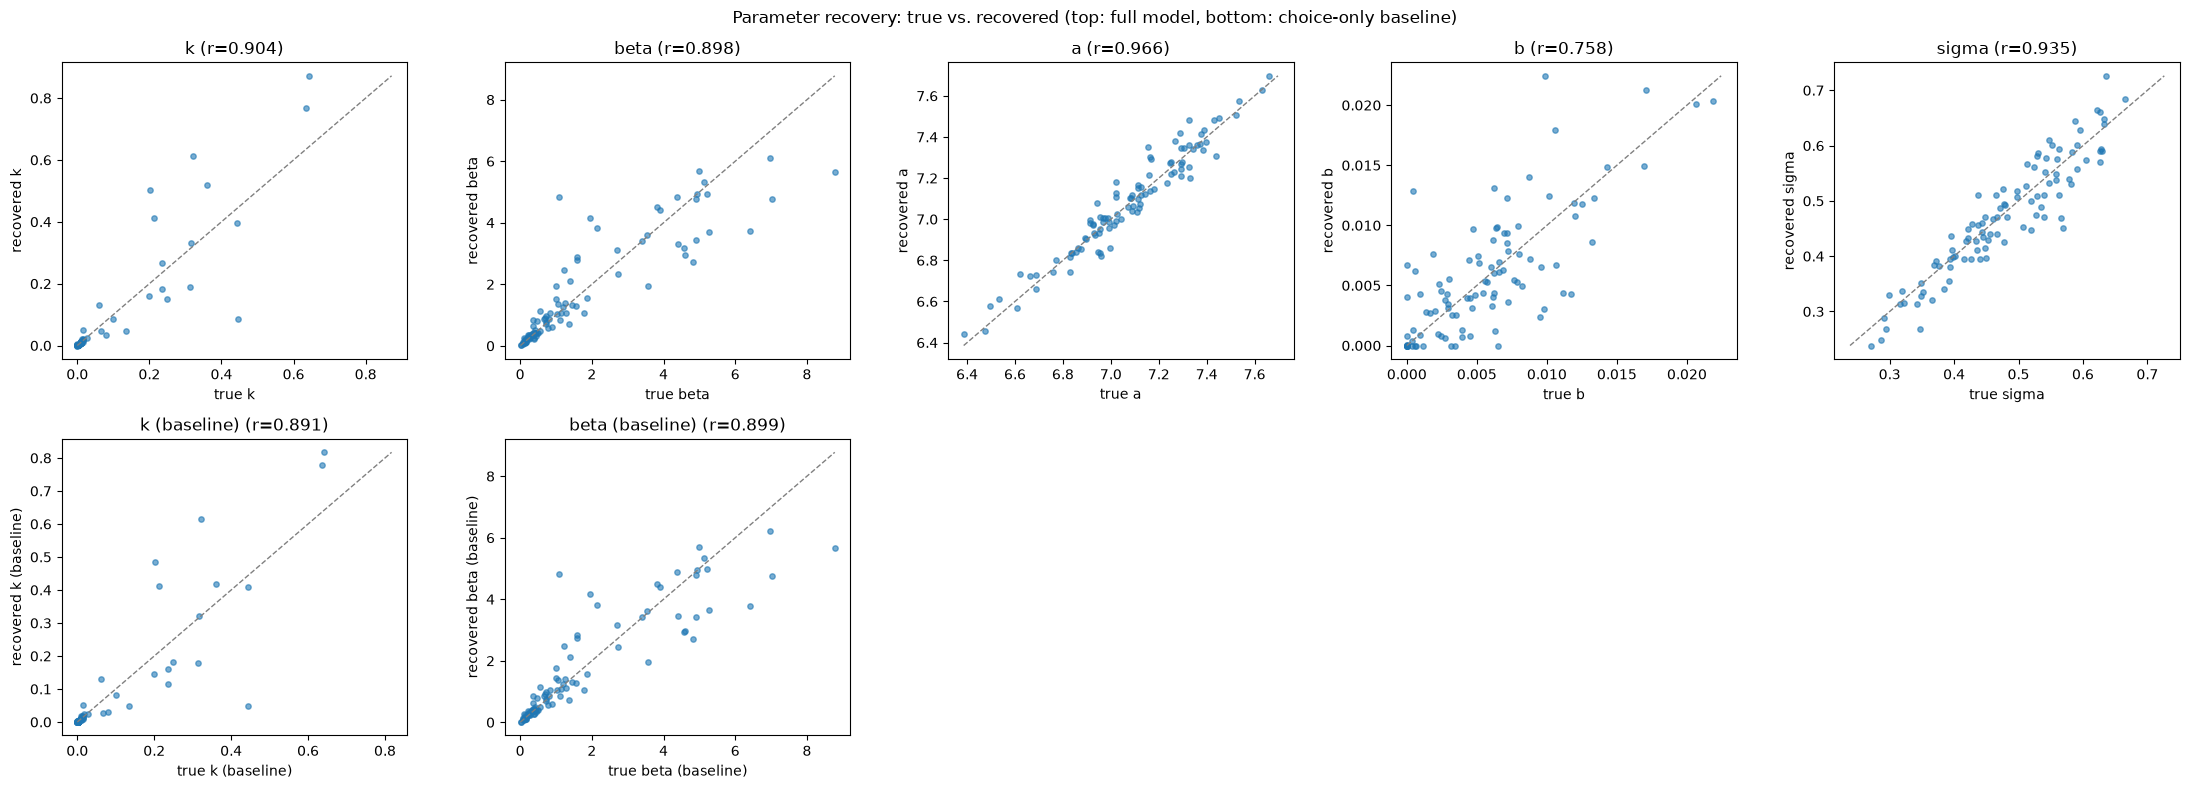

In [28]:
def plot_recovery(ax, true_vals, recovered_vals, name):
    """Scatter true vs. recovered values with a y=x reference line, and
    return the Pearson correlation coefficient.
    """
    r_value, _ = stats.pearsonr(true_vals, recovered_vals)
    ax.scatter(true_vals, recovered_vals, alpha=0.6, s=15)
    lo = min(np.min(true_vals), np.min(recovered_vals))
    hi = max(np.max(true_vals), np.max(recovered_vals))
    ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel(f"true {name}")
    ax.set_ylabel(f"recovered {name}")
    ax.set_title(f"{name} (r={r_value:.3f})")
    return r_value


fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for col, name in enumerate(FULL_PARAM_NAMES):
    plot_recovery(axes[0, col], full_true_df[name].to_numpy(), full_recovered_df[name].to_numpy(), name)
for col, name in enumerate(BASELINE_PARAM_NAMES):
    plot_recovery(
        axes[1, col], baseline_true_df[name].to_numpy(), baseline_recovered_df[name].to_numpy(), f"{name} (baseline)"
    )
for col in range(len(BASELINE_PARAM_NAMES), 5):
    axes[1, col].axis("off")
fig.suptitle("Parameter recovery: true vs. recovered (top: full model, bottom: choice-only baseline)")
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "recovery_scatter_full_and_baseline.png"), dpi=150, bbox_inches="tight")
plt.show()


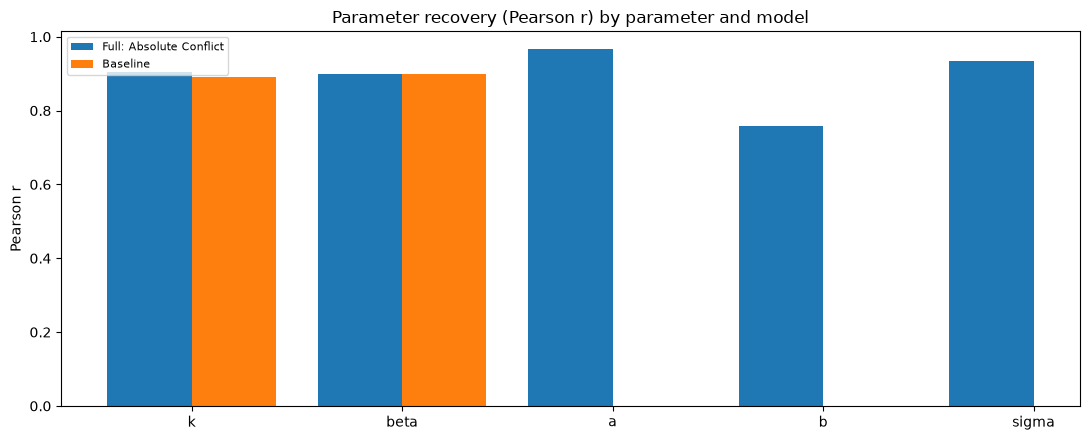

In [29]:
def plot_grouped_bar_by_param(r_long_df, title, ylabel="Pearson r"):
    """Grouped bar chart: x = parameter name (union across all models found),
    one bar group per model_name. Generic over however many models are present
    in r_long_df -- nothing here is hardcoded to a specific count of models.
    """
    param_names_ordered = [p for p in ["k", "beta", "a", "b", "sigma"] if p in r_long_df["param_name"].unique()]
    param_names_ordered += sorted(p for p in r_long_df["param_name"].unique() if p not in param_names_ordered)

    model_names = sorted(r_long_df["model_name"].unique(), key=lambda m: (m == "baseline", m))
    x = np.arange(len(param_names_ordered))
    n_models = len(model_names)
    width = 0.8 / max(n_models, 1)

    fig, ax = plt.subplots(figsize=(2.2 * len(param_names_ordered), 4.5))
    for i, model_name in enumerate(model_names):
        subset = r_long_df[r_long_df["model_name"] == model_name].set_index("param_name")["pearson_r"]
        heights = [subset.get(p, np.nan) for p in param_names_ordered]
        offset = (i - (n_models - 1) / 2) * width
        ax.bar(x + offset, heights, width, label=format_model_label(model_name))

    ax.set_xticks(x)
    ax.set_xticklabels(param_names_ordered)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_grouped_bar_by_param(recovery_r_long, "Parameter recovery (Pearson r) by parameter and model")


In [30]:
recovery_long_full.to_csv(os.path.join(RESULTS_DIR, f"recovery_long_{MODEL_NAME}.csv"), index=False)
print(f"Saved: {os.path.join(RESULTS_DIR, f'recovery_long_{MODEL_NAME}.csv')}")

recovery_long_baseline.to_csv(os.path.join(RESULTS_DIR, "recovery_long_baseline.csv"), index=False)
print(f"Saved: {os.path.join(RESULTS_DIR, 'recovery_long_baseline.csv')}")


Saved: results/recovery_long_absolute_conflict.csv
Saved: results/recovery_long_baseline.csv


## 2.6 Diagnosing `b`'s comparatively low recovery (r=0.758)

Three diagnostic checks: (i) how concentrated the ground-truth `b_true` values are near
zero; (ii) whether the recovered `b` is systematically shrunk toward zero
(via a linear regression of recovered on true); (iii) whether the overall
r=0.758 is mainly driven by the 15 subjects whose recovery fit has `b` stuck
at its lower bound.


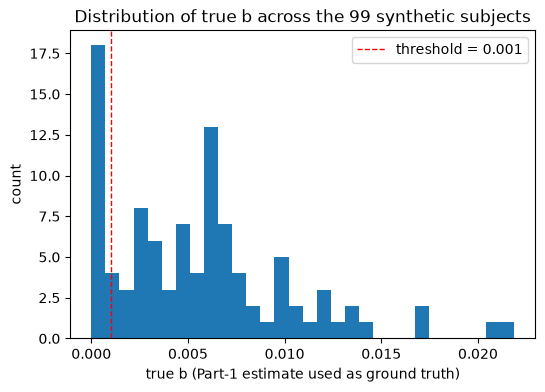

20 / 99 subjects (20.2%) have true b < 0.001


In [31]:
b_true = full_true_df["b"].to_numpy()
b_recovered = full_recovered_df["b"].to_numpy()

NEAR_ZERO_THRESHOLD = 0.001  # chosen relative to b's fitted range in Part 1 (max ~0.022)
n_near_zero = int(np.sum(b_true < NEAR_ZERO_THRESHOLD))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(b_true, bins=30)
ax.axvline(NEAR_ZERO_THRESHOLD, color="red", linestyle="--", linewidth=1, label=f"threshold = {NEAR_ZERO_THRESHOLD}")
ax.set_xlabel("true b (Part-1 estimate used as ground truth)")
ax.set_ylabel("count")
ax.set_title("Distribution of true b across the 99 synthetic subjects")
ax.legend()
fig.savefig(os.path.join(FIGURES_DIR, "b_true_histogram.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"{n_near_zero} / {len(b_true)} subjects ({100 * n_near_zero / len(b_true):.1f}%) have true b < {NEAR_ZERO_THRESHOLD}")


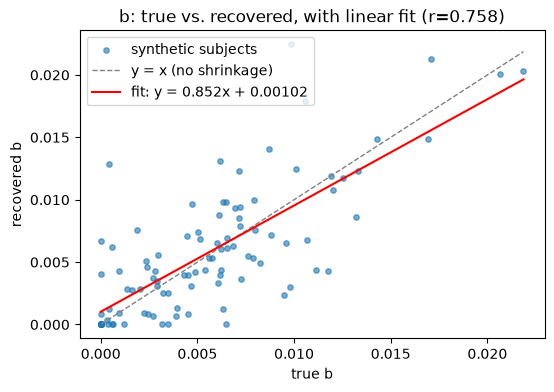

Linear regression of recovered b on true b:
  slope = 0.8517
  intercept = 0.001022
  r_value (from linregress) = 0.7575
  p_value = 1.1435e-19
  std_err (of the slope) = 0.0745


In [32]:
b_slope, b_intercept, b_r_value, b_p_value, b_std_err = stats.linregress(b_true, b_recovered)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(b_true, b_recovered, alpha=0.6, s=15, label="synthetic subjects")
x_line = np.array([b_true.min(), b_true.max()])
ax.plot(x_line, x_line, color="gray", linestyle="--", linewidth=1, label="y = x (no shrinkage)")
ax.plot(x_line, b_slope * x_line + b_intercept, color="red", linewidth=1.5, label=f"fit: y = {b_slope:.3f}x + {b_intercept:.5f}")
ax.set_xlabel("true b")
ax.set_ylabel("recovered b")
ax.set_title(f"b: true vs. recovered, with linear fit (r={b_r_value:.3f})")
ax.legend()
fig.savefig(os.path.join(FIGURES_DIR, "b_true_vs_recovered_regression.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Linear regression of recovered b on true b:")
print(f"  slope = {b_slope:.4f}")
print(f"  intercept = {b_intercept:.6f}")
print(f"  r_value (from linregress) = {b_r_value:.4f}")
print(f"  p_value = {b_p_value:.4e}")
print(f"  std_err (of the slope) = {b_std_err:.4f}")


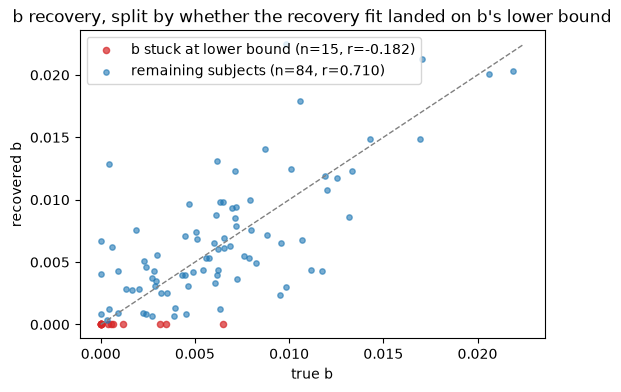

b stuck at lower bound (n=15): Pearson r = -0.1818
remaining subjects (n=84): Pearson r = 0.7105
overall (n=99): Pearson r = 0.7575


In [33]:
b_bound_stuck_ids = set(recovery_full_bound_subjects["b"]["lower"])
subject_ids_in_order = full_true_df.index.to_numpy()
is_bound_stuck = np.array([sid in b_bound_stuck_ids for sid in subject_ids_in_order])

b_true_stuck, b_recovered_stuck = b_true[is_bound_stuck], b_recovered[is_bound_stuck]
b_true_rest, b_recovered_rest = b_true[~is_bound_stuck], b_recovered[~is_bound_stuck]

r_stuck, _ = stats.pearsonr(b_true_stuck, b_recovered_stuck)
r_rest, _ = stats.pearsonr(b_true_rest, b_recovered_rest)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(b_true_stuck, b_recovered_stuck, alpha=0.7, s=20, color="tab:red", label=f"b stuck at lower bound (n={len(b_true_stuck)}, r={r_stuck:.3f})")
ax.scatter(b_true_rest, b_recovered_rest, alpha=0.6, s=15, color="tab:blue", label=f"remaining subjects (n={len(b_true_rest)}, r={r_rest:.3f})")
lo = min(b_true.min(), b_recovered.min())
hi = max(b_true.max(), b_recovered.max())
ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("true b")
ax.set_ylabel("recovered b")
ax.set_title("b recovery, split by whether the recovery fit landed on b's lower bound")
ax.legend()
fig.savefig(os.path.join(FIGURES_DIR, "b_recovery_by_bound_status.png"), dpi=150, bbox_inches="tight")
plt.show()

overall_b_r = recovery_r_long.query("model_name == @MODEL_NAME and param_name == 'b'")["pearson_r"].iloc[0]
print(f"b stuck at lower bound (n={len(b_true_stuck)}): Pearson r = {r_stuck:.4f}")
print(f"remaining subjects (n={len(b_true_rest)}): Pearson r = {r_rest:.4f}")
print(f"overall (n={len(b_true)}): Pearson r = {overall_b_r:.4f}")


# Part 3 — Reliability (run A vs. run B)

Run A's estimates are Part 1's results (`full_fits`, `baseline_fits`),
reused unchanged. Run B is fit completely independently: same likelihoods,
priors, bounds, and candidate-pool procedure, but a distinct random seed, so
run B shares no information with run A beyond using the same fixed
model/priors/bounds every fit in this notebook uses. Only tables are
reported here (no scatter plots).


## 3.1 Fitting run B independently

Reuses `fit_full_candidate_pool` / `fit_baseline_candidate_pool` (Part 1),
applied to each subject's cleaned run-B data.


In [34]:
RUN_B_MULTI_START_SEED = 5059
run_b_rng = np.random.default_rng(RUN_B_MULTI_START_SEED)

run_b_full_fits = {}
run_b_baseline_fits = {}

for subject_id, runs in clean_subjects.items():
    df = runs["test"]
    shift = shift_values[subject_id]
    a_prior_mean = np.log(df["RT"].median())
    run_b_full_fits[subject_id] = fit_full_candidate_pool(df, shift, a_prior_mean, run_b_rng)
    run_b_baseline_fits[subject_id] = fit_baseline_candidate_pool(df, run_b_rng)

print(f"Run B fitting complete for {len(run_b_full_fits)} subjects (full model and baseline).")


Run B fitting complete for 99 subjects (full model and baseline).


## 3.2 Convergence failures and bound-stuck subjects: run A vs. run B

In [35]:
run_a_full_failed = failed_ids(full_fits)
run_b_full_failed = failed_ids(run_b_full_fits)
run_a_baseline_failed = failed_ids(baseline_fits)
run_b_baseline_failed = failed_ids(run_b_baseline_fits)
n_subjects_part3 = len(full_fits)

print("Full model:")
print(f"  run A failed: {len(run_a_full_failed)} / {n_subjects_part3}")
if run_a_full_failed:
    print(f"    subject IDs: {run_a_full_failed}")
print(f"  run B failed: {len(run_b_full_failed)} / {n_subjects_part3}")
if run_b_full_failed:
    print(f"    subject IDs: {run_b_full_failed}")

print("\nChoice-only baseline:")
print(f"  run A failed: {len(run_a_baseline_failed)} / {n_subjects_part3}")
if run_a_baseline_failed:
    print(f"    subject IDs: {run_a_baseline_failed}")
print(f"  run B failed: {len(run_b_baseline_failed)} / {n_subjects_part3}")
if run_b_baseline_failed:
    print(f"    subject IDs: {run_b_baseline_failed}")

run_a_full_bound_counts, run_a_full_bound_subjects = tally_bound_flags(full_fits, FULL_PARAM_NAMES, FULL_BOUNDS)
run_b_full_bound_counts, run_b_full_bound_subjects = tally_bound_flags(run_b_full_fits, FULL_PARAM_NAMES, FULL_BOUNDS)
run_a_baseline_bound_counts, run_a_baseline_bound_subjects = tally_bound_flags(baseline_fits, BASELINE_PARAM_NAMES, BASELINE_BOUNDS)
run_b_baseline_bound_counts, run_b_baseline_bound_subjects = tally_bound_flags(run_b_baseline_fits, BASELINE_PARAM_NAMES, BASELINE_BOUNDS)

print()
print_bound_tally("Full model, run A", run_a_full_bound_counts, run_a_full_bound_subjects, FULL_PARAM_NAMES)
print()
print_bound_tally("Full model, run B", run_b_full_bound_counts, run_b_full_bound_subjects, FULL_PARAM_NAMES)
print()
print_bound_tally("Baseline, run A", run_a_baseline_bound_counts, run_a_baseline_bound_subjects, BASELINE_PARAM_NAMES)
print()
print_bound_tally("Baseline, run B", run_b_baseline_bound_counts, run_b_baseline_bound_subjects, BASELINE_PARAM_NAMES)


Full model:
  run A failed: 0 / 99
  run B failed: 0 / 99

Choice-only baseline:
  run A failed: 1 / 99
    subject IDs: ['Sample1_yzpl1bjpp']
  run B failed: 1 / 99
    subject IDs: ['Sample1_3sdxo9cfd']

Full model, run A:
  k (lower bound): 6 subjects -> ['Sample1_3sdxo9cfd', 'Sample1_f3zeh9jib', 'Sample2_2qwq8xyde', 'Sample2_50qhhzl0l', 'Sample2_k5m1dlbmf', 'Sample2_tvlehk06l']
  b (lower bound): 11 subjects -> ['Sample1_t5fyitpcm', 'Sample1_tqjcijs1e', 'Sample1_vowxbo6kk', 'Sample1_wqbicpk3k', 'Sample2_4vubmw9up', 'Sample2_5jvj7f5y4', 'Sample2_82xbgaiuk', 'Sample2_dyww6xmpp', 'Sample2_mjx6wy2sv', 'Sample2_ot3o7pu2r', 'Sample2_ztvocmqgb']

Full model, run B:
  k (lower bound): 15 subjects -> ['Sample1_1pwx30q0h', 'Sample1_2y7h2y7g1', 'Sample1_3sdxo9cfd', 'Sample1_416jjdnnn', 'Sample1_7wtuwovob', 'Sample1_cml16ebl7', 'Sample1_f3zeh9jib', 'Sample1_js4ftmk17', 'Sample1_mr0at8mm8', 'Sample1_wqbicpk3k', 'Sample1_xlols9pbl', 'Sample2_4vubmw9up', 'Sample2_50qhhzl0l', 'Sample2_plkt7myz0', 

## 3.3 Pearson r and ICC(2,1) between run A and run B estimates, and CSV export

ICC(2,1): two-way random-effects, absolute-agreement, single-measurement
intraclass correlation (Shrout & Fleiss, 1979), computed directly from its
defining ANOVA decomposition for the k=2 "raters" case (run A / run B are
the two measurement occasions).


In [36]:
def icc_2_1(run_a_values, run_b_values):
    """Two-way random-effects, absolute-agreement ICC for a single measurement (k=2 occasions)."""
    data = np.column_stack([np.asarray(run_a_values, dtype=float), np.asarray(run_b_values, dtype=float)])
    n, k = data.shape
    grand_mean = data.mean()
    subject_means = data.mean(axis=1)
    measurement_means = data.mean(axis=0)

    ss_total = np.sum((data - grand_mean) ** 2)
    ss_subjects = k * np.sum((subject_means - grand_mean) ** 2)
    ss_measurements = n * np.sum((measurement_means - grand_mean) ** 2)
    ss_error = ss_total - ss_subjects - ss_measurements

    ms_subjects = ss_subjects / (n - 1)
    ms_measurements = ss_measurements / (k - 1)
    ms_error = ss_error / ((n - 1) * (k - 1))

    return (ms_subjects - ms_error) / (ms_subjects + (k - 1) * ms_error + k * (ms_measurements - ms_error) / n)


run_a_full_df = pd.DataFrame({sid: r["x"] for sid, r in full_fits.items()}).T
run_a_full_df.columns = FULL_PARAM_NAMES
run_b_full_df = pd.DataFrame({sid: r["x"] for sid, r in run_b_full_fits.items()}).T
run_b_full_df.columns = FULL_PARAM_NAMES

run_a_baseline_df = pd.DataFrame({sid: r["x"] for sid, r in baseline_fits.items()}).T
run_a_baseline_df.columns = BASELINE_PARAM_NAMES
run_b_baseline_df = pd.DataFrame({sid: r["x"] for sid, r in run_b_baseline_fits.items()}).T
run_b_baseline_df.columns = BASELINE_PARAM_NAMES


def build_reliability_table(run_a_df, run_b_df, model_name):
    """One row per parameter: model_name, param_name, pearson_r, icc_2_1."""
    rows = []
    for name in run_a_df.columns:
        r_value, _ = stats.pearsonr(run_a_df[name], run_b_df[name])
        icc_value = icc_2_1(run_a_df[name], run_b_df[name])
        rows.append({"model_name": model_name, "param_name": name, "pearson_r": r_value, "icc_2_1": icc_value})
    return pd.DataFrame(rows)


reliability_long_full = build_reliability_table(run_a_full_df, run_b_full_df, MODEL_NAME)
reliability_long_baseline = build_reliability_table(run_a_baseline_df, run_b_baseline_df, "baseline")

reliability_table = pd.concat([reliability_long_full, reliability_long_baseline], ignore_index=True)
print("Run A vs. run B reliability (Pearson r and ICC(2,1)):")
display(reliability_table)


Run A vs. run B reliability (Pearson r and ICC(2,1)):


,model_name,param_name,pearson_r,icc_2_1
0,absolute_conflict,k,0.090783,0.088551
1,absolute_conflict,beta,0.391713,0.381687
2,absolute_conflict,a,0.431808,0.310639
3,absolute_conflict,b,0.228696,0.034864
4,absolute_conflict,sigma,0.261424,0.205502
5,baseline,k,0.248090,0.249015
6,baseline,beta,0.409292,0.396281


In [37]:
reliability_long_full.to_csv(os.path.join(RESULTS_DIR, f"reliability_long_{MODEL_NAME}.csv"), index=False)
print(f"Saved: {os.path.join(RESULTS_DIR, f'reliability_long_{MODEL_NAME}.csv')}")

reliability_long_baseline.to_csv(os.path.join(RESULTS_DIR, "reliability_long_baseline.csv"), index=False)
print(f"Saved: {os.path.join(RESULTS_DIR, 'reliability_long_baseline.csv')}")


Saved: results/reliability_long_absolute_conflict.csv
Saved: results/reliability_long_baseline.csv


## 3.4 Diagnosing full-model `k`'s low run A / run B reliability (r=0.091)

Investigates whether the full model's `k` reliability being lower than the
baseline's `k` reliability is driven by outliers, cross-parameter
entanglement, or a difference in random-start/convergence behaviour.


### 3.4.1 Random-seed / multi-start strategy used for each fit

In [38]:
print("Full model,  run A: single-start heuristic + multi-start draws from")
print(f"  np.random.default_rng(MULTI_START_SEED={MULTI_START_SEED})")
print("Baseline,    run A: draws from the SAME rng object as the full model above -- within")
print("  Part 1's per-subject loop, the full model's 5 random starts (5 draws each = 25")
print("  numbers) are consumed first, then the baseline's 5 random starts (2 draws each =")
print("  10 numbers) are consumed next from that same sequentially-advancing generator.")
print("  Full model and baseline in run A are therefore NOT drawing from independent")
print("  random streams; they share one stream, consumed in a fixed order.")
print()
print("Full model,  run B: single-start heuristic + multi-start draws from")
print(f"  np.random.default_rng(RUN_B_MULTI_START_SEED={RUN_B_MULTI_START_SEED})")
print("Baseline,    run B: draws from the SAME run_b_rng object, consumed immediately after")
print("  the full model's draws for that subject -- same sharing pattern as run A, just")
print("  with a different seed value.")
print()
print(f"Run A ({MULTI_START_SEED}) and run B ({RUN_B_MULTI_START_SEED}) use DIFFERENT seeds /")
print("streams from each other, by design (independent fitting, no information shared")
print("between run A and run B).")


Full model,  run A: single-start heuristic + multi-start draws from
  np.random.default_rng(MULTI_START_SEED=2024)
Baseline,    run A: draws from the SAME rng object as the full model above -- within
  Part 1's per-subject loop, the full model's 5 random starts (5 draws each = 25
  numbers) are consumed first, then the baseline's 5 random starts (2 draws each =
  10 numbers) are consumed next from that same sequentially-advancing generator.
  Full model and baseline in run A are therefore NOT drawing from independent
  random streams; they share one stream, consumed in a fixed order.

Full model,  run B: single-start heuristic + multi-start draws from
  np.random.default_rng(RUN_B_MULTI_START_SEED=5059)
Baseline,    run B: draws from the SAME run_b_rng object, consumed immediately after
  the full model's draws for that subject -- same sharing pattern as run A, just
  with a different seed value.

Run A (2024) and run B (5059) use DIFFERENT seeds /
streams from each other, by design (i

### 3.4.2 Run A vs. run B scatter data for full-model `k`, with outlier check

In [39]:
k_run_a = run_a_full_df["k"].to_numpy()
k_run_b = run_b_full_df["k"].to_numpy()
k_subject_ids = run_a_full_df.index.to_numpy()

k_abs_diff = np.abs(k_run_a - k_run_b)
k_order = np.argsort(k_abs_diff)[::-1]

print("Top 10 subjects by |run A k - run B k|:")
for idx in k_order[:10]:
    print(f"  {k_subject_ids[idx]}: run_a_k={k_run_a[idx]:.4f}, run_b_k={k_run_b[idx]:.4f}, |diff|={k_abs_diff[idx]:.4f}")

r_k_all, _ = stats.pearsonr(k_run_a, k_run_b)
print(f"\nPearson r, full-model k, all 99 subjects: {r_k_all:.4f}")

mask_minus1 = np.ones(len(k_run_a), dtype=bool)
mask_minus1[k_order[0]] = False
r_k_minus1, _ = stats.pearsonr(k_run_a[mask_minus1], k_run_b[mask_minus1])
print(f"Pearson r excluding the single most extreme subject ({k_subject_ids[k_order[0]]}): {r_k_minus1:.4f}")

mask_minus2 = mask_minus1.copy()
mask_minus2[k_order[1]] = False
r_k_minus2, _ = stats.pearsonr(k_run_a[mask_minus2], k_run_b[mask_minus2])
print(f"Pearson r excluding the two most extreme subjects: {r_k_minus2:.4f}")


Top 10 subjects by |run A k - run B k|:
  Sample2_rok227idr: run_a_k=0.0099, run_b_k=1.1507, |diff|=1.1408
  Sample1_k0gmonjdn: run_a_k=0.0159, run_b_k=0.8165, |diff|=0.8005
  Sample2_k8r16gj2b: run_a_k=0.6357, run_b_k=0.0269, |diff|=0.6088
  Sample1_9v9a0mzog: run_a_k=0.0011, run_b_k=0.5056, |diff|=0.5045
  Sample1_iyx44wgf4: run_a_k=0.0118, run_b_k=0.5135, |diff|=0.5017
  Sample2_4z5b6fuid: run_a_k=0.4451, run_b_k=0.0063, |diff|=0.4387
  Sample1_2rw7x91oz: run_a_k=0.4427, run_b_k=0.0253, |diff|=0.4175
  Sample1_3vkv0cbe1: run_a_k=0.0011, run_b_k=0.3575, |diff|=0.3564
  Sample2_in8hftao9: run_a_k=0.3601, run_b_k=0.0070, |diff|=0.3530
  Sample1_fp18o4fwe: run_a_k=0.0099, run_b_k=0.3474, |diff|=0.3375

Pearson r, full-model k, all 99 subjects: 0.0908
Pearson r excluding the single most extreme subject (Sample2_rok227idr): 0.1530
Pearson r excluding the two most extreme subjects: 0.2198


### 3.4.3 Same outlier-removal analysis for the baseline's `k` (control comparison), and direct comparison

In [40]:
k_run_a_baseline = run_a_baseline_df["k"].to_numpy()
k_run_b_baseline = run_b_baseline_df["k"].to_numpy()
k_baseline_subject_ids = run_a_baseline_df.index.to_numpy()

k_baseline_abs_diff = np.abs(k_run_a_baseline - k_run_b_baseline)
k_baseline_order = np.argsort(k_baseline_abs_diff)[::-1]

r_k_baseline_all, _ = stats.pearsonr(k_run_a_baseline, k_run_b_baseline)

k_baseline_r_by_n = {0: r_k_baseline_all}
for n in [1, 2, 3, 5]:
    mask_n = np.ones(len(k_run_a_baseline), dtype=bool)
    mask_n[k_baseline_order[:n]] = False
    r_n, _ = stats.pearsonr(k_run_a_baseline[mask_n], k_run_b_baseline[mask_n])
    k_baseline_r_by_n[n] = r_n

k_full_r_by_n = {0: r_k_all, 1: r_k_minus1, 2: r_k_minus2}
for n in [3, 5]:
    mask_n = np.ones(len(k_run_a), dtype=bool)
    mask_n[k_order[:n]] = False
    r_n, _ = stats.pearsonr(k_run_a[mask_n], k_run_b[mask_n])
    k_full_r_by_n[n] = r_n

comparison_rows = [
    {
        "outliers_removed": n,
        "r_full_model": k_full_r_by_n[n],
        "r_baseline": k_baseline_r_by_n[n],
        "difference (full - baseline)": k_full_r_by_n[n] - k_baseline_r_by_n[n],
    }
    for n in [0, 1, 2, 3, 5]
]
k_reliability_comparison_table = pd.DataFrame(comparison_rows)
print("k reliability, full model vs. baseline, with progressive outlier removal:")
display(k_reliability_comparison_table)


k reliability, full model vs. baseline, with progressive outlier removal:


,outliers_removed,r_full_model,r_baseline,difference (full - baseline)
0,0,0.090783,0.248090,-0.157307
1,1,0.152984,0.353164,-0.200180
2,2,0.219828,0.409202,-0.189374
3,3,0.250942,0.532093,-0.281151
4,5,0.396125,0.679661,-0.283536


### 3.4.4 Within-run correlation of `k` with the other full-model parameters

In [41]:
print("Run A (full model): correlation of k with each other parameter")
for name in ["beta", "a", "b", "sigma"]:
    r_val, _ = stats.pearsonr(run_a_full_df["k"], run_a_full_df[name])
    print(f"  k vs {name}: r = {r_val:.4f}")

print("\nRun B (full model): correlation of k with each other parameter")
for name in ["beta", "a", "b", "sigma"]:
    r_val, _ = stats.pearsonr(run_b_full_df["k"], run_b_full_df[name])
    print(f"  k vs {name}: r = {r_val:.4f}")


Run A (full model): correlation of k with each other parameter
  k vs beta: r = -0.1752
  k vs a: r = -0.0054
  k vs b: r = -0.0359
  k vs sigma: r = 0.0750

Run B (full model): correlation of k with each other parameter
  k vs beta: r = -0.1471
  k vs a: r = 0.0364
  k vs b: r = -0.0952
  k vs sigma: r = 0.1146


### 3.4.5 `k` convergence failures / bound-stuck counts: full model vs. baseline, run A vs. run B

In [42]:
print("Convergence failures (whole fit, not k-specific):")
print(f"  Full model,  run A: {len(run_a_full_failed)} / {n_subjects_part3}")
print(f"  Full model,  run B: {len(run_b_full_failed)} / {n_subjects_part3}")
print(f"  Baseline,    run A: {len(run_a_baseline_failed)} / {n_subjects_part3}")
print(f"  Baseline,    run B: {len(run_b_baseline_failed)} / {n_subjects_part3}")

print("\nSubjects with k stuck at its lower bound:")
print(f"  Full model,  run A: {run_a_full_bound_counts['k']['lower']} -> {run_a_full_bound_subjects['k']['lower']}")
print(f"  Full model,  run B: {run_b_full_bound_counts['k']['lower']} -> {run_b_full_bound_subjects['k']['lower']}")
print(f"  Baseline,    run A: {run_a_baseline_bound_counts['k']['lower']} -> {run_a_baseline_bound_subjects['k']['lower']}")
print(f"  Baseline,    run B: {run_b_baseline_bound_counts['k']['lower']} -> {run_b_baseline_bound_subjects['k']['lower']}")


Convergence failures (whole fit, not k-specific):
  Full model,  run A: 0 / 99
  Full model,  run B: 0 / 99
  Baseline,    run A: 1 / 99
  Baseline,    run B: 1 / 99

Subjects with k stuck at its lower bound:
  Full model,  run A: 6 -> ['Sample1_3sdxo9cfd', 'Sample1_f3zeh9jib', 'Sample2_2qwq8xyde', 'Sample2_50qhhzl0l', 'Sample2_k5m1dlbmf', 'Sample2_tvlehk06l']
  Full model,  run B: 15 -> ['Sample1_1pwx30q0h', 'Sample1_2y7h2y7g1', 'Sample1_3sdxo9cfd', 'Sample1_416jjdnnn', 'Sample1_7wtuwovob', 'Sample1_cml16ebl7', 'Sample1_f3zeh9jib', 'Sample1_js4ftmk17', 'Sample1_mr0at8mm8', 'Sample1_wqbicpk3k', 'Sample1_xlols9pbl', 'Sample2_4vubmw9up', 'Sample2_50qhhzl0l', 'Sample2_plkt7myz0', 'Sample2_tvlehk06l']
  Baseline,    run A: 5 -> ['Sample1_3sdxo9cfd', 'Sample1_f3zeh9jib', 'Sample2_2qwq8xyde', 'Sample2_50qhhzl0l', 'Sample2_tvlehk06l']
  Baseline,    run B: 19 -> ['Sample1_1pwx30q0h', 'Sample1_2y7h2y7g1', 'Sample1_3sdxo9cfd', 'Sample1_416jjdnnn', 'Sample1_7wtuwovob', 'Sample1_cml16ebl7', 'Samp

# Part 4 — Out-of-sample Prediction and Value of the RT Modality

Uses each subject's **run-A-fitted** parameters (Part 1's `full_fits`,
`baseline_fits` — not refit here) to predict their **run-B** data.
Predictive log-likelihood uses the raw likelihood only (no prior term,
since this is an out-of-sample evaluation, not MAP estimation).


**Data check:** predictive metrics are reported separately for the reward
and loss conditions. This data set contains only reward-condition trials, as
the raw `condition` counts below show:


In [43]:
train_condition_counts = pd.concat([runs["train"]["condition"] for runs in raw_subjects.values()]).value_counts()
test_condition_counts = pd.concat([runs["test"]["condition"] for runs in raw_subjects.values()]).value_counts()
print("Raw data_train condition value counts (all 99 subjects):")
print(train_condition_counts.to_string())
print("\nRaw data_test condition value counts (all 99 subjects):")
print(test_condition_counts.to_string())


Raw data_train condition value counts (all 99 subjects):
condition
1.0    8920

Raw data_test condition value counts (all 99 subjects):
condition
1.0    20070


Every trial, in every subject, in both runs, has `condition == 1`
(reward); there are zero `condition == 2` (loss) trials anywhere in this
data set, in both the Sample1 and Sample2 sub-samples. This is a property
of the raw data and holds regardless of which RT model is fitted, so Part 4
below computes metrics directly for the (only) reward condition, without a
condition-splitting loop.


## 4.1 Per-trial predictive likelihood functions

Standalone per-trial versions of the choice/RT log-likelihood (mirror the
logic in `choice_log_likelihood` / `rt_log_likelihood` from Part 1 exactly,
without the final `.sum()`), so predictive log-likelihood can be broken down
by subject.


In [44]:
def choice_log_lik_per_trial(df, k, beta):
    """Per-trial log p(choice | delta_V, beta), no summation."""
    delta_v = compute_delta_v(df, k)
    chose_delayed = df["choice"].to_numpy() == 2
    sign = np.where(chose_delayed, 1.0, -1.0)
    return log_sigmoid(sign * beta * delta_v)


def choice_prob_delayed(df, k, beta):
    """P(delayed) per trial, under the same softmax rule used in choice_log_likelihood."""
    delta_v = compute_delta_v(df, k)
    return 1.0 / (1.0 + np.exp(-beta * delta_v))


def rt_log_lik_per_trial(df, k, a, b, sigma, shift, mu_func=MU_FUNC):
    """Per-trial log-density of RT under the shifted log-normal, no summation."""
    delta_v = compute_delta_v(df, k)
    mu = mu_func(delta_v, a, b)
    rt_shifted = df["RT"].to_numpy() - shift
    log_rt_shifted = np.log(rt_shifted)
    return (
        -log_rt_shifted - np.log(sigma) - 0.5 * np.log(2 * np.pi) - (log_rt_shifted - mu) ** 2 / (2 * sigma ** 2)
    )


## 4.2 Computing per-subject predictive metrics on run B, and CSV export

One row per subject. `rt_log_lik_*` is left `NaN` for the baseline (it has
no RT term). This per-subject long table is what the summary table and both
histograms below are built from.


In [45]:
predictive_rows_full = []
predictive_rows_baseline = []

for subject_id, runs in clean_subjects.items():
    df_b = runs["test"][runs["test"]["condition"] == 1]  # the only condition with data
    shift = shift_values[subject_id]

    k_full, beta_full, a_full, b_full, sigma_full = full_fits[subject_id]["x"]
    k_base, beta_base = baseline_fits[subject_id]["x"]

    choice_ll_full = choice_log_lik_per_trial(df_b, k_full, beta_full)
    p_delayed_full = choice_prob_delayed(df_b, k_full, beta_full)
    predicted_full = np.where(p_delayed_full > 0.5, 2.0, 1.0)
    correct_full = predicted_full == df_b["choice"].to_numpy()
    rt_ll_full = rt_log_lik_per_trial(df_b, k_full, a_full, b_full, sigma_full, shift)

    predictive_rows_full.append(
        {
            "subject_id": subject_id,
            "model_name": MODEL_NAME,
            "n_trials": len(df_b),
            "choice_log_lik_sum": choice_ll_full.sum(),
            "choice_log_lik_mean": choice_ll_full.mean(),
            "choice_n_correct": int(correct_full.sum()),
            "choice_accuracy": correct_full.mean(),
            "rt_log_lik_sum": rt_ll_full.sum(),
            "rt_log_lik_mean": rt_ll_full.mean(),
        }
    )

    choice_ll_base = choice_log_lik_per_trial(df_b, k_base, beta_base)
    p_delayed_base = choice_prob_delayed(df_b, k_base, beta_base)
    predicted_base = np.where(p_delayed_base > 0.5, 2.0, 1.0)
    correct_base = predicted_base == df_b["choice"].to_numpy()

    predictive_rows_baseline.append(
        {
            "subject_id": subject_id,
            "model_name": "baseline",
            "n_trials": len(df_b),
            "choice_log_lik_sum": choice_ll_base.sum(),
            "choice_log_lik_mean": choice_ll_base.mean(),
            "choice_n_correct": int(correct_base.sum()),
            "choice_accuracy": correct_base.mean(),
            "rt_log_lik_sum": np.nan,
            "rt_log_lik_mean": np.nan,
        }
    )

predictive_long_full = pd.DataFrame(predictive_rows_full)
predictive_long_baseline = pd.DataFrame(predictive_rows_baseline)

print(f"Computed predictive metrics for {len(predictive_long_full)} subjects (full model).")
print(f"Computed predictive metrics for {len(predictive_long_baseline)} subjects (baseline).")


Computed predictive metrics for 99 subjects (full model).
Computed predictive metrics for 99 subjects (baseline).


In [46]:
predictive_long_full.to_csv(os.path.join(RESULTS_DIR, f"predictive_long_{MODEL_NAME}.csv"), index=False)
print(f"Saved: {os.path.join(RESULTS_DIR, f'predictive_long_{MODEL_NAME}.csv')}")

predictive_long_baseline.to_csv(os.path.join(RESULTS_DIR, "predictive_long_baseline.csv"), index=False)
print(f"Saved: {os.path.join(RESULTS_DIR, 'predictive_long_baseline.csv')}")


Saved: results/predictive_long_absolute_conflict.csv
Saved: results/predictive_long_baseline.csv


## 4.3 Predictive Performance: summary table (pooled) and RT predictive log-likelihood

**Pooled** means every run-B trial from every subject is summed/counted
together before computing the metric (so subjects with more trials
contribute proportionally more).


In [47]:
def pooled_predictive_summary(long_df_by_model):
    """One row per model: n_subjects, n_trials, choice log-lik/trial, choice accuracy,
    RT log-lik/trial (NaN if the model's table has no rt_log_lik, e.g. baseline).
    Pooled across all subjects' trials.
    """
    rows = []
    for model_name, df in long_df_by_model.items():
        n_trials = df["n_trials"].sum()
        choice_log_lik_mean = df["choice_log_lik_sum"].sum() / n_trials
        choice_accuracy = df["choice_n_correct"].sum() / n_trials
        if df["rt_log_lik_sum"].notna().any():
            rt_log_lik_mean = df["rt_log_lik_sum"].sum() / n_trials
        else:
            rt_log_lik_mean = np.nan
        rows.append(
            {
                "model": format_model_label(model_name),
                "n_subjects": df["subject_id"].nunique(),
                "n_trials_pooled": n_trials,
                "choice_log_lik_mean_per_trial_pooled": choice_log_lik_mean,
                "choice_accuracy_pooled": choice_accuracy,
                "rt_log_lik_mean_per_trial_pooled": rt_log_lik_mean,
            }
        )
    return pd.DataFrame(rows)


predictive_tables_by_model = {MODEL_NAME: predictive_long_full, "baseline": predictive_long_baseline}
predictive_summary_table = pooled_predictive_summary(predictive_tables_by_model)
print("Out-of-sample predictive performance on run B (reward condition; run-A-fitted parameters):")
display(predictive_summary_table)


Out-of-sample predictive performance on run B (reward condition; run-A-fitted parameters):


,model,n_subjects,n_trials_pooled,choice_log_lik_mean_per_trial_pooled,choice_accuracy_pooled,rt_log_lik_mean_per_trial_pooled
0,Full: Absolute Conflict,99,19681,-1.679202,0.681368,-8.397343
1,Baseline,99,19681,-1.481232,0.685636,NaN


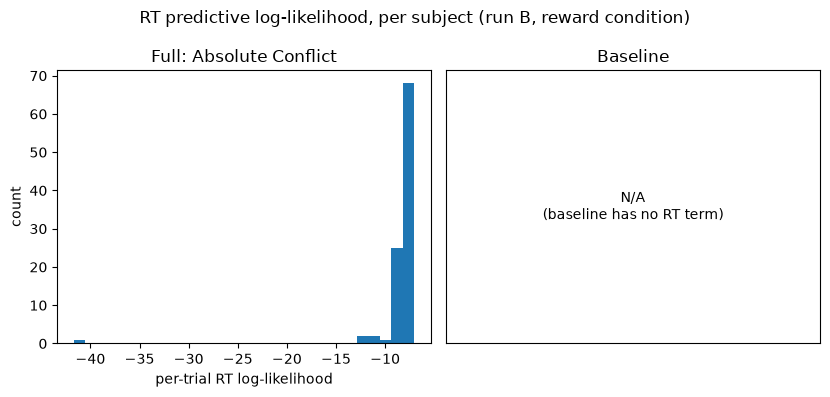

In [48]:
def plot_rt_loglik_histograms(rt_model_tables):
    """One panel per RT model found in rt_model_tables, plus one fixed trailing
    'baseline (N/A)' panel (RT log-likelihood is structurally undefined for the
    choice-only baseline, not just \"not yet available\"). Generic over however
    many RT models are present -- nothing here is hardcoded to a specific count.
    """
    n_rt_models = len(rt_model_tables)
    n_panels = n_rt_models + 1
    fig, axes = plt.subplots(1, n_panels, figsize=(4.2 * n_panels, 4))
    if n_panels == 1:
        axes = [axes]

    for ax, (model_name, df) in zip(axes, rt_model_tables.items()):
        ax.hist(df["rt_log_lik_mean"].dropna(), bins=30)
        ax.set_xlabel("per-trial RT log-likelihood")
        ax.set_ylabel("count")
        ax.set_title(format_model_label(model_name))

    baseline_ax = axes[-1]
    baseline_ax.text(0.5, 0.5, "N/A\n(baseline has no RT term)", ha="center", va="center", transform=baseline_ax.transAxes)
    baseline_ax.set_title("Baseline")
    baseline_ax.set_xticks([])
    baseline_ax.set_yticks([])

    fig.suptitle("RT predictive log-likelihood, per subject (run B, reward condition)")
    plt.tight_layout()
    plt.show()


plot_rt_loglik_histograms({MODEL_NAME: predictive_long_full})


## 4.4 Value of the RT Modality

For each RT model found, the per-subject difference in choice predictive
log-likelihood (that RT model minus the choice-only baseline) is
histogrammed. One panel per RT model present; this is
generic, not hardcoded to a specific count of models.


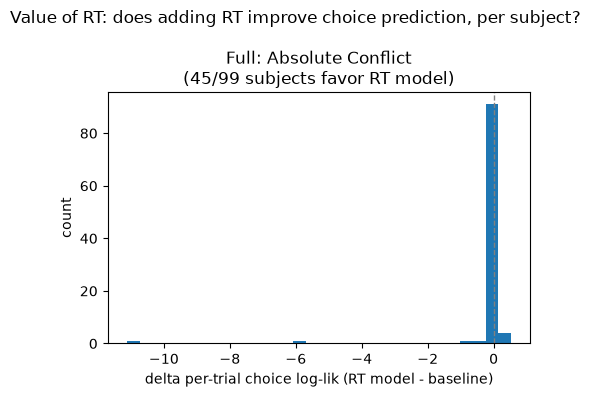

In [49]:
def plot_delta_choice_loglik_histograms(rt_model_tables, baseline_table):
    """One panel per RT model in rt_model_tables, delta = that model's per-subject
    choice_log_lik_mean minus the baseline's, joined on subject_id.
    """
    n_rt_models = len(rt_model_tables)
    if n_rt_models == 0:
        print("  no RT-model predictive tables found -- skipping this panel.")
        return

    fig, axes = plt.subplots(1, n_rt_models, figsize=(5 * n_rt_models, 4))
    if n_rt_models == 1:
        axes = [axes]

    for ax, (model_name, df) in zip(axes, rt_model_tables.items()):
        merged = df.merge(baseline_table, on="subject_id", suffixes=("_rt", "_baseline"))
        delta = merged["choice_log_lik_mean_rt"] - merged["choice_log_lik_mean_baseline"]
        ax.hist(delta, bins=30)
        ax.axvline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_xlabel("delta per-trial choice log-lik (RT model - baseline)")
        ax.set_ylabel("count")
        n_better = int((delta > 0).sum())
        ax.set_title(f"{format_model_label(model_name)}\n({n_better}/{len(delta)} subjects favor RT model)")

    fig.suptitle("Value of RT: does adding RT improve choice prediction, per subject?")
    plt.tight_layout()
    plt.show()


plot_delta_choice_loglik_histograms({MODEL_NAME: predictive_long_full}, predictive_long_baseline)


# Additional checks

Numbers quoted in the text that the cells above do not print directly:
(a) the number of missing-choice trials (`choice == 0`) in the raw data, and
how many of them also contain a NaN (and are therefore already removed by
the NaN step of the preprocessing); (b) how many subjects' run-B choices are
better predicted by the full model than by the choice-only baseline; (c) the
run-A `beta` of the two subjects with the largest run-B choice
log-likelihood loss for the full model, and their share of the total loss;
(d) the number of subjects in Sample1 and Sample2 and each sample's
per-subject run-A and run-B trial counts before cleaning. Reads only
`DD_data/` and `results/`.


In [50]:
import glob
import os

import numpy as np
import pandas as pd
import scipy.io as sio

# (a) Missing-choice trials in the raw data (column 4 is the choice; 0 = missing)
n_missing_choice = 0
n_missing_choice_with_nan = 0
for filepath in sorted(glob.glob(os.path.join("DD_data", "*.mat"))):
    mat = sio.loadmat(filepath)
    for key in ["data_train", "data_test"]:
        data = mat[key]
        is_missing_choice = data[:, 3] == 0
        n_missing_choice += int(is_missing_choice.sum())
        n_missing_choice_with_nan += int((is_missing_choice & np.isnan(data).any(axis=1)).sum())

print("(a) Raw data, all 99 subjects, run A + run B:")
print(f"  trials with choice == 0: {n_missing_choice}")
print(f"  of these, trials that also contain a NaN: {n_missing_choice_with_nan}")

# (b) Per-subject difference in run-B choice log-likelihood per trial (full model minus baseline)
full_pred = pd.read_csv(os.path.join("results", "predictive_long_absolute_conflict.csv"))
baseline_pred = pd.read_csv(os.path.join("results", "predictive_long_baseline.csv"))
merged_pred = full_pred.merge(baseline_pred, on="subject_id", suffixes=("_full", "_baseline"))
delta_choice_ll = merged_pred["choice_log_lik_mean_full"] - merged_pred["choice_log_lik_mean_baseline"]

print("\n(b) Run-B choice log-likelihood per trial, full model minus baseline:")
print(f"  full model better: {int((delta_choice_ll > 0).sum())} / {len(delta_choice_ll)} subjects")
print(f"  baseline better: {int((delta_choice_ll < 0).sum())} / {len(delta_choice_ll)} subjects")
print(f"  tied: {int((delta_choice_ll == 0).sum())} / {len(delta_choice_ll)} subjects")

# (c) The two subjects with the largest full-model loss in run-B choice prediction.
# Their run-A full-model beta is the ground truth used in parameter recovery
# (recovery_long true_value = Part 1 run-A estimate).
recovery_full = pd.read_csv(os.path.join("results", "recovery_long_absolute_conflict.csv"))
run_a_beta = recovery_full[recovery_full["param_name"] == "beta"].set_index("subject_id")["true_value"]
delta_choice_ll_sum = (merged_pred["choice_log_lik_sum_full"] - merged_pred["choice_log_lik_sum_baseline"]).to_numpy()
delta_by_subject = pd.Series(delta_choice_ll_sum, index=merged_pred["subject_id"])
focus_subjects = ["Sample2_f9w51nwmr", "Sample2_plkt7myz0"]

print("\n(c) Run-A full-model beta and run-B choice log-likelihood (summed over trials, full model minus baseline):")
print(f"  median run-A beta across {len(run_a_beta)} subjects: {run_a_beta.median():.3f}")
for subject_id in focus_subjects:
    print(f"  {subject_id}: run-A beta = {run_a_beta[subject_id]:.3f}, difference = {delta_by_subject[subject_id]:.1f}")
total_delta = delta_by_subject.sum()
focus_delta = delta_by_subject[focus_subjects].sum()
print(f"  total difference, all {len(delta_by_subject)} subjects: {total_delta:.1f}")
print(f"  the two subjects combined: {focus_delta:.1f} ({100 * focus_delta / total_delta:.1f}% of the total)")

# (d) Sample sizes and per-subject trial counts before cleaning, straight from the .mat files
trial_counts = {"Sample1": [], "Sample2": []}
for filepath in sorted(glob.glob(os.path.join("DD_data", "*.mat"))):
    sample = os.path.basename(filepath).split("_")[0]
    mat = sio.loadmat(filepath)
    trial_counts[sample].append((mat["data_train"].shape[0], mat["data_test"].shape[0]))


def format_count_range(values):
    return str(min(values)) if min(values) == max(values) else f"{min(values)}-{max(values)}"


print("\n(d) Subjects and per-subject trial counts before cleaning:")
for sample, counts in trial_counts.items():
    run_a_counts = [run_a for run_a, _ in counts]
    run_b_counts = [run_b for _, run_b in counts]
    print(
        f"  {sample}: {len(counts)} subjects, run A = {format_count_range(run_a_counts)} trials, "
        f"run B = {format_count_range(run_b_counts)} trials per subject"
    )


(a) Raw data, all 99 subjects, run A + run B:
  trials with choice == 0: 93
  of these, trials that also contain a NaN: 93

(b) Run-B choice log-likelihood per trial, full model minus baseline:
  full model better: 45 / 99 subjects
  baseline better: 54 / 99 subjects
  tied: 0 / 99 subjects

(c) Run-A full-model beta and run-B choice log-likelihood (summed over trials, full model minus baseline):
  median run-A beta across 99 subjects: 0.719
  Sample2_f9w51nwmr: run-A beta = 6.403, difference = -2492.0
  Sample2_plkt7myz0: run-A beta = 4.566, difference = -1366.0
  total difference, all 99 subjects: -3896.2
  the two subjects combined: -3858.0 (99.0% of the total)

(d) Subjects and per-subject trial counts before cleaning:
  Sample1: 49 subjects, run A = 80 trials, run B = 180 trials per subject
  Sample2: 50 subjects, run A = 100 trials, run B = 225 trials per subject
